# Financial Econometrics with Python 



In [75]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats
import scipy.signal as ss
from scipy.stats import gaussian_kde, norm, skew, kurtosis, jarque_bera, anderson
from statsmodels.stats.diagnostic import lilliefors, het_arch, acorr_ljungbox
from scipy.optimize import minimize
from statsmodels.tsa.stattools import acf, acovf
from statsmodels.iolib.summary2 import summary_col

# QUESTION 1
## Preliminary step 1: data

In [76]:
ticker = "JPM"
sample_start = "1950-01-01"
sample_end = "2026-01-01"  # excluded by yfinance: last observation = last trading day of 2025

JPM = yf.download(ticker, start=sample_start, end=sample_end)

[*********************100%***********************]  1 of 1 completed


In [77]:
Pt_d = JPM["Close"]
Pt_d = Pt_d.rename(columns={Pt_d.columns[0]: "Pt.d"})
Pt_d.index = pd.to_datetime(Pt_d.index)

pt_d = np.log(Pt_d).squeeze("columns")
pt_w = pt_d.resample('W').last()
pt_m = pt_d.resample('ME').last()
pt_y = pt_d.resample('YE').last()

rt_d = pt_d.diff().dropna()
rt_w = pt_w.diff().dropna()
rt_m = pt_m.diff().dropna()
rt_y = pt_y.diff().dropna()

## Preliminary step 2: sample description and summary statistics

In [78]:
print("Ticker:", ticker)
print("First date:", pt_d.index[0].date())
print("Last date:", pt_d.index[-1].date())
print("Length (years):", round((pt_d.index[-1] - pt_d.index[0]).days / 365.25, 2))
print("N. daily prices:", len(pt_d))
print("N. months:", len(pt_m))
print("N. calendar years:", len(pt_y))
print("N. returns daily / weekly / monthly / annual:", len(rt_d), len(rt_w), len(rt_m), len(rt_y))

Ticker: JPM
First date: 1980-03-17
Last date: 2025-12-31
Length (years): 45.79
N. daily prices: 11543
N. months: 550
N. calendar years: 46
N. returns daily / weekly / monthly / annual: 11542 2389 549 45


In [79]:
def summary_statistics(x):
    stat_tab = {
        'Mean': round(np.mean(x) * 100, 5),
        'St.Deviation': round(np.std(x) * 100, 5),
        'Diameter.C.I.Mean': round(1.96 * np.sqrt(np.var(x) / len(x)) * 100, 5),
        'Skewness': round(skew(x), 5),
        'Kurtosis': round(kurtosis(x) + 3, 5),
        'Excess.Kurtosis': round(kurtosis(x), 5),
        'Min': round(np.min(x) * 100, 5),
        'Quant5': round(np.quantile(x, 0.05) * 100, 5),
        'Quant25': round(np.quantile(x, 0.25) * 100, 5),
        'Median': round(np.quantile(x, 0.50) * 100, 5),
        'Quant75': round(np.quantile(x, 0.75) * 100, 5),
        'Quant95': round(np.quantile(x, 0.95) * 100, 5),
        'Max': round(np.max(x) * 100, 5),
        'Jarque.Bera.stat': round(jarque_bera(x)[0], 5),
        'Jarque.Bera.pvalue.X100': round(jarque_bera(x)[1] * 100, 5),
        'Lillie.test.stat': round(lilliefors(x)[0], 5),
        'Lillie.test.pvalue.X100': round(lilliefors(x)[1] * 100, 5),
        'N.obs': len(x)
    }
    return stat_tab

**Table: summary statistics of JPM log-returns by frequency (daily, weekly, monthly, annual)**

In [80]:
returns_by_frequency = {
    'daily': rt_d,
    'weekly': rt_w,
    'monthly': rt_m,
    'annual': rt_y
}

summary_table = pd.DataFrame({key: summary_statistics(data) for key, data in returns_by_frequency.items()})
summary_table

,daily,weekly,monthly,annual
Mean,0.04967,0.23847,1.03968,12.23812
St.Deviation,2.20471,4.74616,9.03637,30.42183
Diameter.C.I.Mean,0.04022,0.19032,0.75590,8.88864
Skewness,-0.10565,-0.20987,-0.74346,-0.96416
Kurtosis,18.28989,11.80739,5.54974,4.90077
Excess.Kurtosis,15.28989,8.80739,2.54974,1.90077
Min,-32.46128,-41.68439,-42.58323,-92.35964
Quant5,-3.15356,-7.27926,-13.94165,-35.21497
Quant25,-0.94484,-2.06340,-3.62202,-5.69384
Median,0.00000,0.30253,1.41445,11.04514


**Table: summary statistics of JPM daily log-returns, with and without the week of the October 1987 crash**

In [81]:
crash_date = pd.to_datetime('1987-10-18')
rt_d_noOct87crash = rt_d[~((rt_d.index >= crash_date) & (rt_d.index < crash_date + pd.DateOffset(7)))]

returns_with_without_crash = {
    "daily all": rt_d,
    "daily NO 87 Crash": rt_d_noOct87crash
}

summary_table_crash = pd.DataFrame({key: summary_statistics(data) for key, data in returns_with_without_crash.items()})
summary_table_crash

,daily all,daily NO 87 Crash
Mean,0.04967,0.05194
St.Deviation,2.20471,2.18202
Diameter.C.I.Mean,0.04022,0.03982
Skewness,-0.10565,0.16564
Kurtosis,18.28989,14.75538
Excess.Kurtosis,15.28989,11.75538
Min,-32.46128,-23.22779
Quant5,-3.15356,-3.15152
Quant25,-0.94484,-0.94467
Median,0.00000,0.00000


**Table: summary statistics of JPM daily log-returns by sub-period (4 sub-periods of equal length)**

In [82]:
n_blocks = 4
bounds = np.linspace(0, len(rt_d), n_blocks + 1).astype(int)
sub_periods = [rt_d.iloc[bounds[i]:bounds[i + 1]] for i in range(n_blocks)]

sub_period_table = pd.DataFrame({f"{x.index[0].year}-{x.index[-1].year}": summary_statistics(x) for x in sub_periods})
sub_period_table

,1980-1991,1991-2003,2003-2014,2014-2025
Mean,0.04220,0.04444,0.04076,0.07129
St.Deviation,2.05524,2.36937,2.59926,1.68780
Diameter.C.I.Mean,0.07500,0.08645,0.09485,0.06158
Skewness,-1.31123,0.12566,0.32803,-0.08317
Kurtosis,28.15617,7.41366,18.87726,16.13539
Excess.Kurtosis,25.15617,4.41366,15.87726,13.13539
Min,-32.46128,-19.97645,-23.22779,-16.21056
Quant5,-2.93970,-3.61709,-3.56388,-2.52274
Quant25,-0.98766,-1.27939,-0.90103,-0.69907
Median,0.00000,0.00000,0.02712,0.07140


## Stylized fact 2: returns are stationary

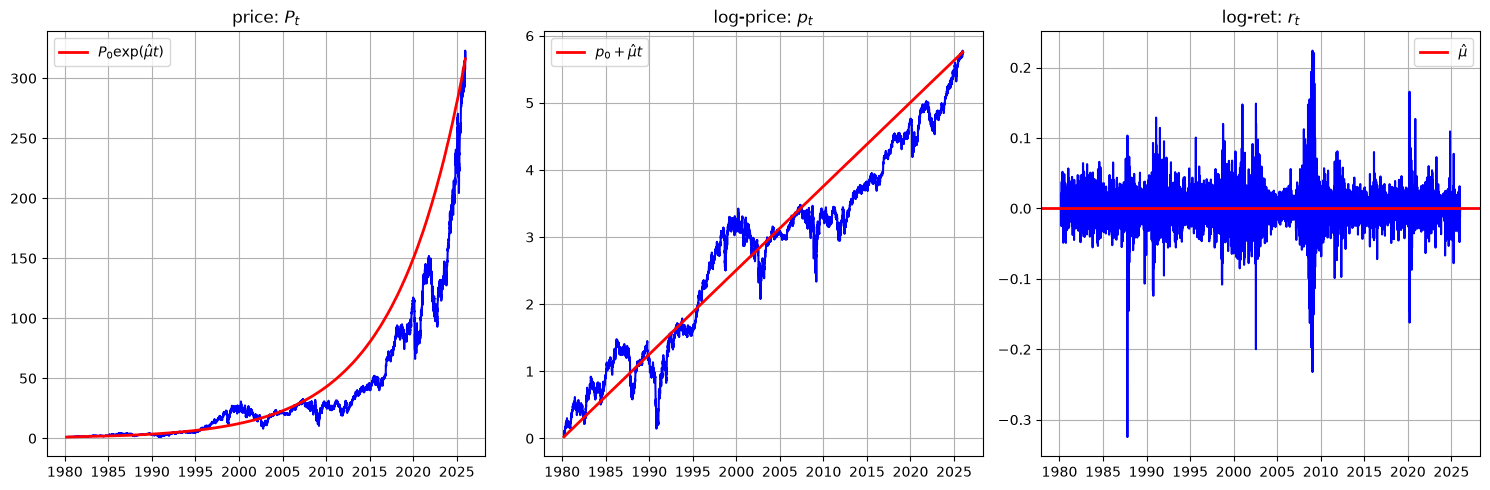

In [83]:
mu_hat = np.mean(rt_d)
t = np.arange(len(pt_d))
P0 = Pt_d.iloc[0, 0]
p0 = pt_d.iloc[0]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].plot(Pt_d.index, Pt_d, color='blue')
axs[0].plot(Pt_d.index, P0 * np.exp(mu_hat * t), color='red', linewidth=2, label=r'$P_0 \exp(\hat{\mu} t)$')
axs[0].set_title('price: $P_t$')
axs[0].legend()
axs[0].grid(True)
axs[1].plot(pt_d.index, pt_d, color='blue')
axs[1].plot(pt_d.index, p0 + mu_hat * t, color='red', linewidth=2, label=r'$p_0 + \hat{\mu} t$')
axs[1].set_title('log-price: $p_t$')
axs[1].legend()
axs[1].grid(True)
axs[2].plot(rt_d.index, rt_d, color='blue')
axs[2].axhline(mu_hat, color='red', linewidth=2, label=r'$\hat{\mu}$')
axs[2].set_title('log-ret: $r_t$')
axs[2].legend()
axs[2].grid(True)
plt.tight_layout()
plt.show()

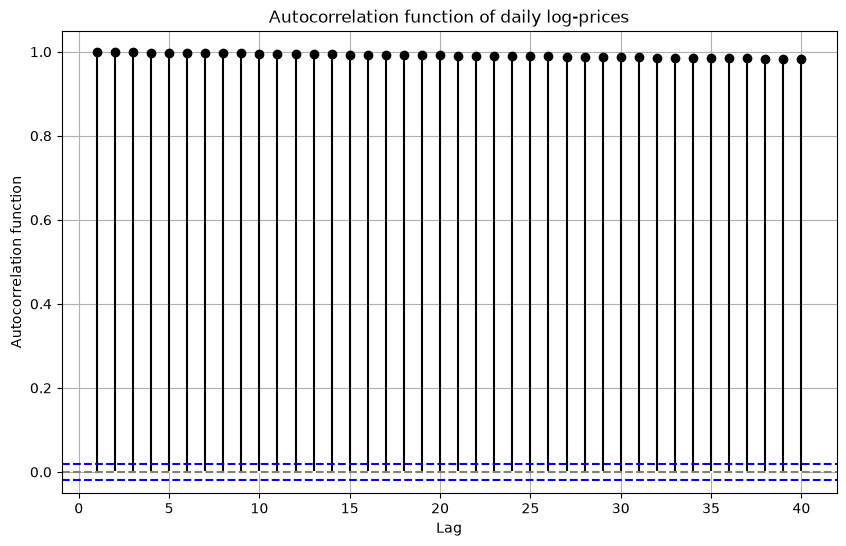

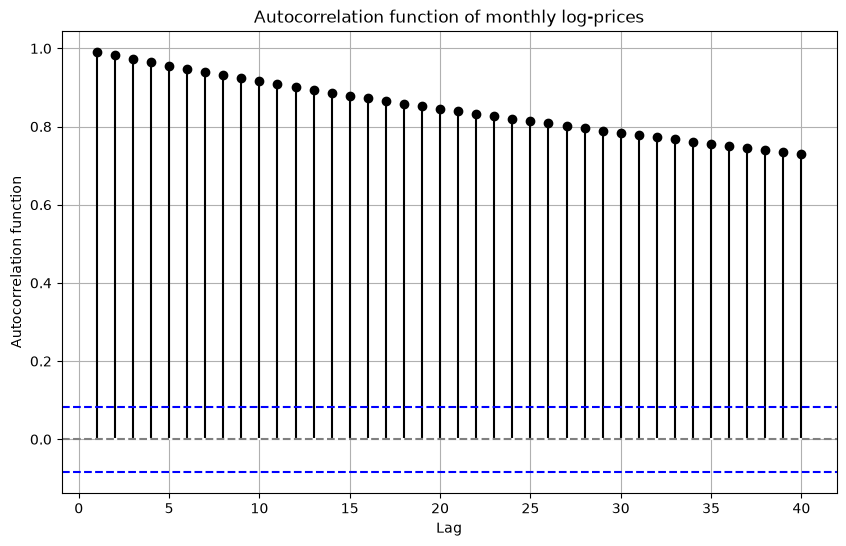

In [84]:
def plot_autocorrelation_function_with_bartlett_bands(x, title, lags=40):
    autocorrelation_function_values = acf(x, nlags=lags)
    Bart_Int = 1.96 / np.sqrt(len(x))
    plt.figure(figsize=(10, 6))
    plt.stem(np.arange(1, lags + 1), autocorrelation_function_values[1:], linefmt='k-', markerfmt='ko', basefmt='w-')
    plt.axhline(y=0, color='gray', linestyle='--')
    plt.axhline(y=Bart_Int, color='blue', linestyle='--')
    plt.axhline(y=-Bart_Int, color='blue', linestyle='--')
    plt.title(title)
    plt.xlabel('Lag')
    plt.ylabel('Autocorrelation function')
    plt.grid(True)
    plt.show()

plot_autocorrelation_function_with_bartlett_bands(pt_d, 'Autocorrelation function of daily log-prices')
plot_autocorrelation_function_with_bartlett_bands(pt_m, 'Autocorrelation function of monthly log-prices')

**Table: autocorrelation function of daily log-prices and daily log-returns at selected lags, with the Bartlett diameter 1.96 / sqrt(N)**

In [85]:
def autocorrelation_function_table(series_by_name, lags=(1, 5, 20, 60, 125, 250)):
    table = {}
    for name, x in series_by_name.items():
        autocorrelation_function_values = acf(x, nlags=max(lags))
        table[name] = {f"lag {lag}": autocorrelation_function_values[lag] for lag in lags}
        table[name]["Bartlett diam."] = 1.96 / np.sqrt(len(x))
    return pd.DataFrame(table).round(4)


autocorrelation_function_table({"daily log-prices": pt_d, "daily log-returns": rt_d})

,daily log-prices,daily log-returns
lag 1,0.9995,-0.0323
lag 5,0.9978,0.0060
lag 20,0.9913,0.0239
lag 60,0.9745,0.0068
lag 125,0.9485,0.0009
lag 250,0.9025,0.0039
Bartlett diam.,0.0182,0.0182


Rolling moments (252 days)

In [86]:
def rolling_moments(returns, window_length):
    T = returns.shape[0]
    roll_mom_manual = np.full((T, 5), np.nan)
    for i in range(window_length, T):
        est_window = np.arange(i - window_length + 1, i + 1)
        y = returns.iloc[est_window]
        roll_mom_manual[i, 0] = np.mean(y)
        roll_mom_manual[i, 1] = np.std(y, ddof=1)
        roll_mom_manual[i, 2] = skew(y)
        roll_mom_manual[i, 3] = kurtosis(y) + 3
        roll_mom_manual[i, 4] = np.mean((y - np.mean(y))**4)
    return roll_mom_manual


def plot_rolling_moment(moment, lower_bound, upper_bound, index, ylabel, title, ylim=None, zero_line=True):
    data2plot = pd.DataFrame({'Moment': moment, 'LowerBound': lower_bound, 'UpperBound': upper_bound}, index=index).dropna()
    date_labels = pd.date_range(start=index[0], end=index[-1], freq='YE-DEC')
    formatted_labels = [f'Dec-{date.year}' if date.year % 3 == 0 else '' for date in date_labels]
    plt.xticks(date_labels, formatted_labels, rotation=45)
    plt.plot(data2plot.index, data2plot["Moment"], color='blue', linestyle='-', linewidth=2)
    plt.plot(data2plot.index, data2plot["LowerBound"], color='red', linestyle='-', linewidth=1)
    plt.plot(data2plot.index, data2plot["UpperBound"], color='red', linestyle='-', linewidth=1)
    if ylim is not None:
        plt.ylim(ylim)
    if zero_line:
        plt.axhline(0, linestyle='-', color='black', linewidth=1)
    plt.grid(True)
    plt.xlabel('')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

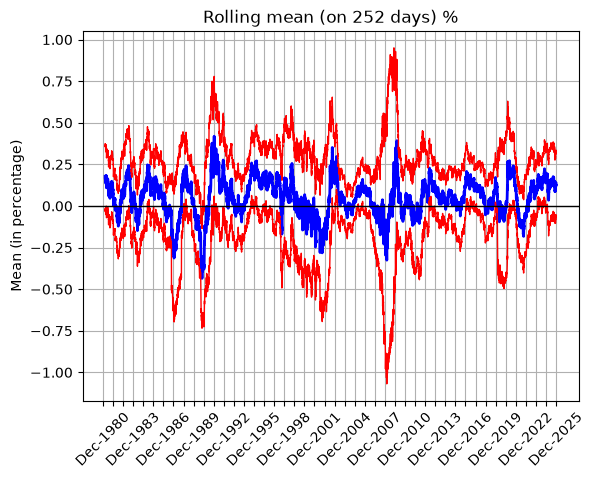

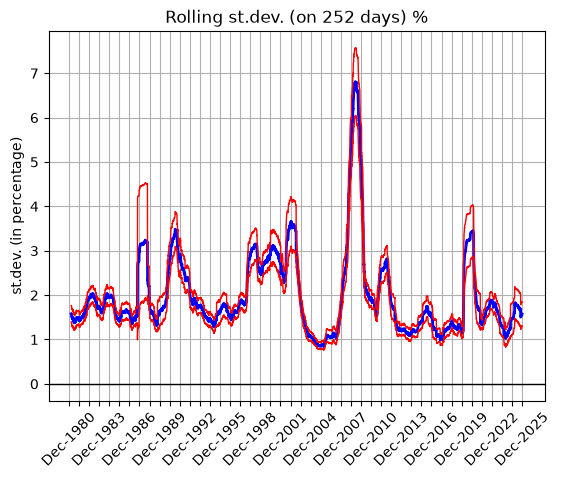

In [87]:
window_length = 252
roll_mom = rolling_moments(rt_d, window_length)

roll_mean = roll_mom[:, 0]
roll_sd = roll_mom[:, 1]
roll_mu4 = roll_mom[:, 4]

plot_rolling_moment(roll_mean * 100,
                    (roll_mean - 1.96 * roll_sd / np.sqrt(window_length)) * 100,
                    (roll_mean + 1.96 * roll_sd / np.sqrt(window_length)) * 100,
                    rt_d.index, 'Mean (in percentage)', 'Rolling mean (on 252 days) %')

roll_sd_se = (1 / (2 * roll_sd) * np.sqrt(roll_mu4 - roll_sd**4)) / np.sqrt(window_length)
plot_rolling_moment(roll_sd * 100,
                    (roll_sd - 1.96 * roll_sd_se) * 100,
                    (roll_sd + 1.96 * roll_sd_se) * 100,
                    rt_d.index, 'st.dev. (in percentage)', 'Rolling st.dev. (on 252 days) %')

Mean, variance and autocovariance on non-overlapping blocks, with linear trend

In [88]:
def block_moments(returns, block_length):
    n_blocks = len(returns) // block_length
    rows = []
    for i in range(n_blocks):
        y = returns.iloc[i * block_length:(i + 1) * block_length]
        rows.append({
            "Date": y.index[block_length // 2],
            "Mean (%)": np.mean(y) * 100,
            "Variance (%²)": np.var(y) * 10000,
            "Autocovariance lag 1 (%²)": acovf(y, nlag=1)[1] * 10000
        })
    return pd.DataFrame(rows).set_index("Date")


def plot_block_moments_with_trend(block_table, block_length, unit="days"):
    years = np.asarray((block_table.index - block_table.index[0]).days / 365.25)
    X = np.column_stack((np.ones(len(years)), years))
    slopes = {}
    fig, axs = plt.subplots(1, 3, figsize=(20, 5))
    for ax, moment in zip(axs, block_table.columns):
        reg = sm.OLS(block_table[moment].values, X).fit()
        slopes[moment] = {"Slope (per year)": round(reg.params[1], 4),
                          "t-stat (H0: slope = 0)": round(reg.tvalues[1], 4) if moment == "Mean (%)" else "",
                          "p-value": round(reg.pvalues[1], 4) if moment == "Mean (%)" else ""}
        ax.scatter(block_table.index, block_table[moment], color="blue", s=15)
        ax.plot(block_table.index, reg.predict(X), color="red", linewidth=2)
        ax.axhline(0, color="black", linewidth=1)
        ax.set_title(f"{moment} - blocks of {block_length} {unit}\nslope = {reg.params[1]:.4f} per year")
        ax.grid(True)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(slopes)

**Daily log-returns, blocks of 50 days: mean, variance and lag-1 autocovariance per block, with linear trend (table: slope per year; t-stat and p-value reported for the mean only)**

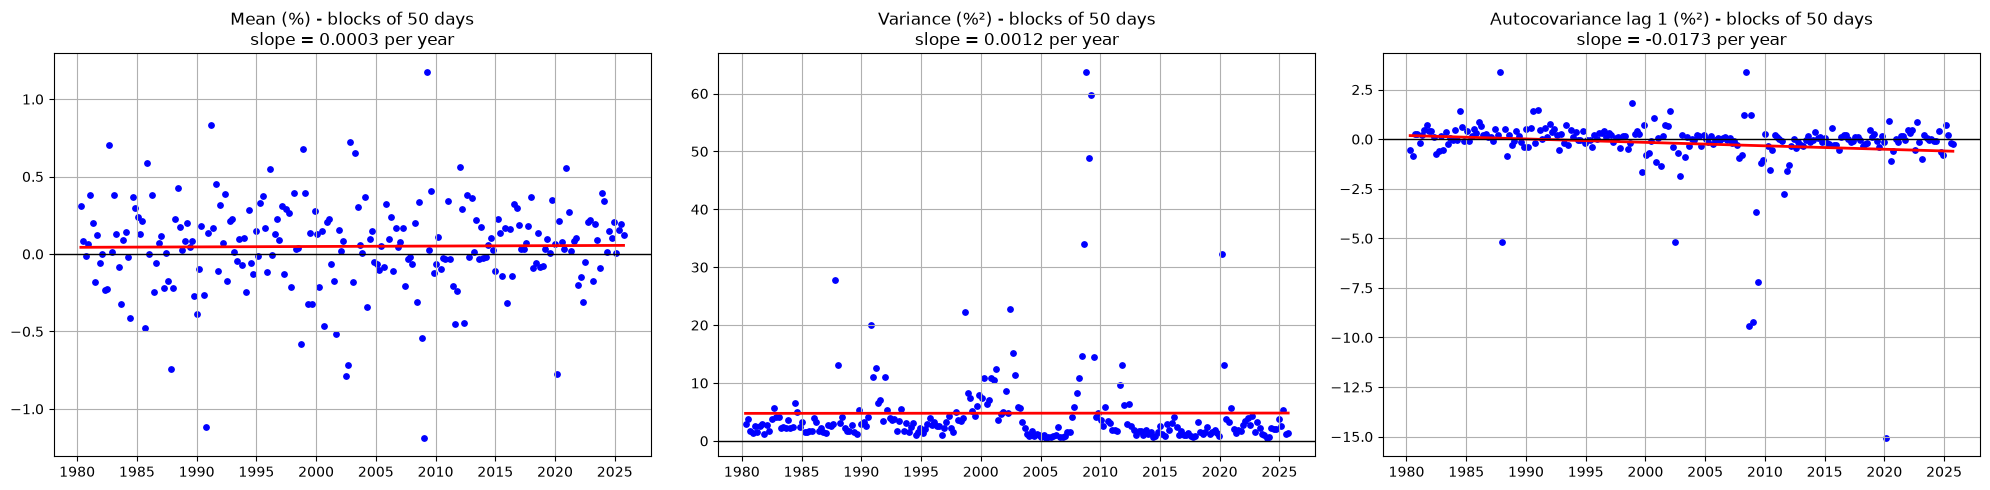

,Mean (%),Variance (%²),Autocovariance lag 1 (%²)
Slope (per year),0.0003,0.0012,-0.0173
t-stat (H0: slope = 0),0.1847,,
p-value,0.8536,,


In [89]:
block_moments_50 = block_moments(rt_d, 50)
plot_block_moments_with_trend(block_moments_50, 50)

**Monthly log-returns, blocks of 12 months: mean, variance and lag-1 autocovariance per block, with linear trend (table: slope per year; t-stat and p-value reported for the mean only)**

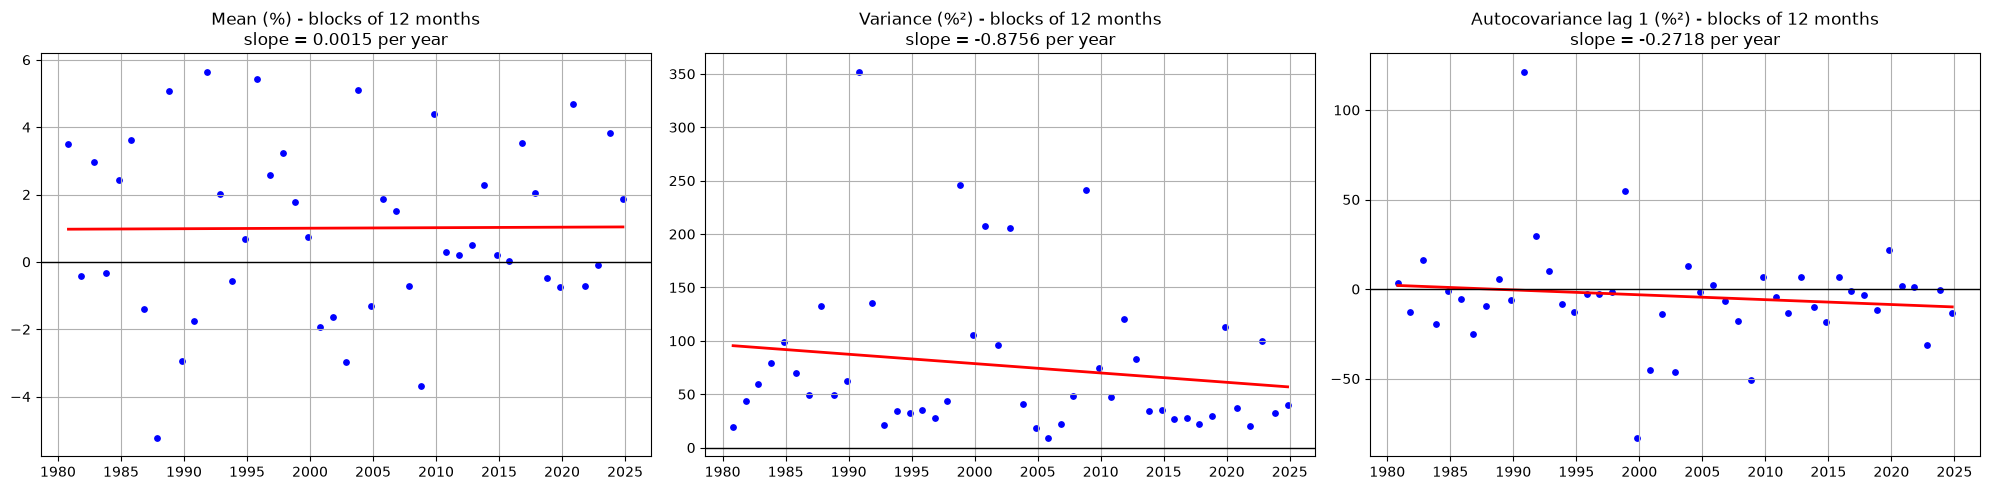

,Mean (%),Variance (%²),Autocovariance lag 1 (%²)
Slope (per year),0.0015,-0.8756,-0.2718
t-stat (H0: slope = 0),0.0509,,
p-value,0.9596,,


In [90]:
block_moments_monthly_12 = block_moments(rt_m, 12)
plot_block_moments_with_trend(block_moments_monthly_12, 12, unit="months")

Homogeneity test across blocks (pooled within-block variance): H0 = same mean / variance / autocovariance in all blocks

In [91]:
def block_homogeneity_test(returns, block_length):
    n_blocks = len(returns) // block_length
    block_values = {"Mean": [], "Variance": [], "Autocovariance lag 1": []}
    overall_mean = np.mean(returns.values)
    for i in range(n_blocks):
        y = returns.iloc[i * block_length:(i + 1) * block_length].values
        deviations = y - np.mean(y)
        block_values["Mean"].append(y)
        block_values["Variance"].append((y - overall_mean)**2)
        block_values["Autocovariance lag 1"].append(deviations[1:] * deviations[:-1])
    results = {}
    for moment in block_values:
        values = np.array(block_values[moment])
        n_per_block = values.shape[1]
        theta = values.mean(axis=1)
        within_block_variance = np.sum((values - theta[:, None])**2) / (values.size - n_blocks)
        Q = n_per_block * np.sum((theta - np.mean(theta))**2) / within_block_variance
        results[moment] = {"Q stat": Q,
                           "df": n_blocks - 1,
                           "Q / df": Q / (n_blocks - 1),
                           "Critical value 5%": stats.chi2.ppf(0.95, n_blocks - 1),
                           "p-value": stats.chi2.sf(Q, n_blocks - 1)}
    return pd.DataFrame(results).round(4)

**Table: homogeneity test across blocks – daily log-returns, blocks of 50 days**

In [92]:
block_homogeneity_test(rt_d, 50)

,Mean,Variance,Autocovariance lag 1
Q stat,201.7021,2017.1968,243.1490
df,229.0000,229.0000,229.0000
Q / df,0.8808,8.8087,1.0618
Critical value 5%,265.3012,265.3012,265.3012
p-value,0.9030,0.0000,0.2486


**Table: homogeneity test across blocks – monthly log-returns, blocks of 12 months**

In [93]:
block_homogeneity_test(rt_m, 12)

,Mean,Variance,Autocovariance lag 1
Q stat,42.5308,108.7817,39.9560
df,44.0000,44.0000,44.0000
Q / df,0.9666,2.4723,0.9081
Critical value 5%,60.4809,60.4809,60.4809
p-value,0.5347,0.0000,0.6456


## Stylized fact 3: asymmetry (negative skewness at all sampling frequencies)
One-sided test, H0: S = 0 vs H1: S < 0, with z = S / sqrt(6/N) (asymptotic distribution of the sample skewness under normality). Reject H0 at 5% if z < -1.645.

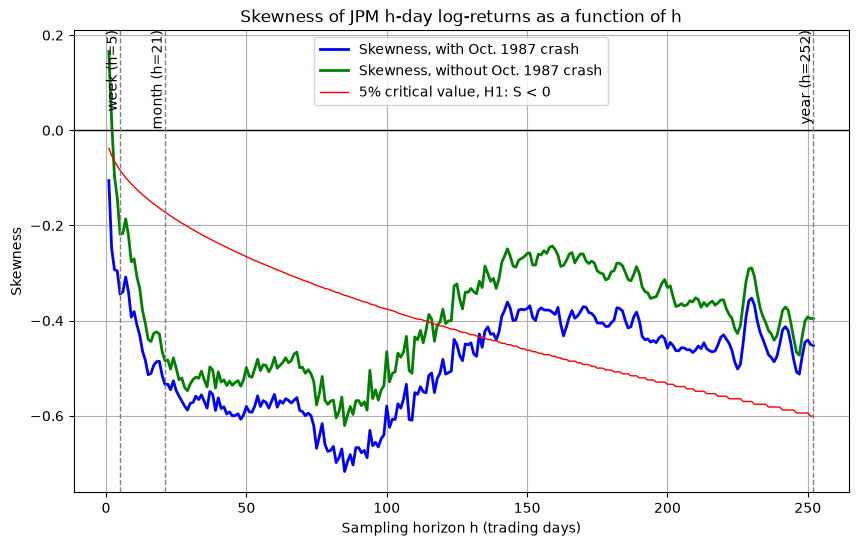

In [94]:
def skewness_by_horizon(log_prices, max_horizon=252):
    mean_skewness = {}
    for h in range(1, max_horizon + 1):
        mean_skewness[h] = np.mean([skew(log_prices.iloc[start::h].diff().dropna()) for start in range(h)])
    return pd.Series(mean_skewness, name="Skewness")

skewness_horizon = skewness_by_horizon(pt_d)

pt_d_noOct87crash = pd.concat([pt_d.iloc[:1], pt_d.iloc[0] + rt_d_noOct87crash.cumsum()])
skewness_horizon_noOct87crash = skewness_by_horizon(pt_d_noOct87crash)

horizons = skewness_horizon.index.values
N_horizon = (len(pt_d) - 1) // horizons
critical_line = -1.645 * np.sqrt(6 / N_horizon)

plt.figure(figsize=(10, 6))
plt.plot(horizons, skewness_horizon, color='blue', linewidth=2, label='Skewness, with Oct. 1987 crash')
plt.plot(horizons, skewness_horizon_noOct87crash, color='green', linewidth=2, label='Skewness, without Oct. 1987 crash')
plt.plot(horizons, critical_line, color='red', linewidth=1, label='5% critical value, H1: S < 0')
plt.axhline(0, color='black', linewidth=1)
for h, label in zip([5, 21, 252], ['week (h=5)', 'month (h=21)', 'year (h=252)']):
    plt.axvline(h, color='gray', linestyle='--', linewidth=1)
    plt.text(h, plt.ylim()[1], label, rotation=90, va='top', ha='right')
plt.xlabel('Sampling horizon h (trading days)')
plt.ylabel('Skewness')
plt.title('Skewness of JPM h-day log-returns as a function of h')
plt.legend()
plt.grid(True)
plt.show()

**Crossing horizon: first h at which the skewness is no longer significantly negative (z > -1.645), and last h at which it still is**

In [95]:
def crossing_horizons(skewness_curve, log_prices):
    N = (len(log_prices) - 1) // skewness_curve.index.values
    z = skewness_curve.values / np.sqrt(6 / N)
    significant = z < -1.645
    return {"First h not significant": skewness_curve.index[~significant][0] if (~significant).any() else None,
            "Last h significant": skewness_curve.index[significant][-1] if significant.any() else None,
            "Number of h significant (out of 252)": int(significant.sum())}

pd.DataFrame({"with Oct. 1987 crash": crossing_horizons(skewness_horizon, pt_d),
              "without Oct. 1987 crash": crossing_horizons(skewness_horizon_noOct87crash, pt_d_noOct87crash)})

,with Oct. 1987 crash,without Oct. 1987 crash
First h not significant,133,1
Last h significant,134,118
Number of h significant (out of 252),133,114


**Table: skewness of JPM log-returns at daily, weekly, monthly and annual horizons, with and without the October 1987 crash, one-sided test H0: S = 0 vs H1: S < 0**

Here h = 1, 5, 21 and 252 are numbers of trading days. The h = 5 column is therefore not the same as the weekly returns of the summary statistics table, which are sampled on calendar weeks.

In [96]:
selected_horizons = [1, 5, 21, 252]
N_selected = (len(pt_d) - 1) // np.array(selected_horizons)
N_selected_noOct87crash = (len(pt_d_noOct87crash) - 1) // np.array(selected_horizons)
S_selected = skewness_horizon.loc[selected_horizons].values
S_selected_noOct87crash = skewness_horizon_noOct87crash.loc[selected_horizons].values
z_selected = S_selected / np.sqrt(6 / N_selected)
z_selected_noOct87crash = S_selected_noOct87crash / np.sqrt(6 / N_selected_noOct87crash)

pd.DataFrame({
    "h (trading days)": selected_horizons,
    "N": N_selected,
    "Skewness (with crash)": S_selected,
    "z (with crash)": z_selected,
    "p-value (with crash)": stats.norm.cdf(z_selected),
    "Skewness (without crash)": S_selected_noOct87crash,
    "z (without crash)": z_selected_noOct87crash,
    "p-value (without crash)": stats.norm.cdf(z_selected_noOct87crash)
}, index=["daily", "weekly", "monthly", "annual"]).round(4)

,h (trading days),N,Skewness (with crash),z (with crash),p-value (with crash),Skewness (without crash),z (without crash),p-value (without crash)
daily,1,11542,-0.1056,-4.6337,0.0000,0.1656,7.2632,1.0000
weekly,5,2308,-0.3443,-6.7526,0.0000,-0.2184,-4.2826,0.0000
monthly,21,549,-0.5344,-5.1114,0.0000,-0.4842,-4.6319,0.0000
annual,252,45,-0.4525,-1.2392,0.1076,-0.3954,-1.0827,0.1395


## Stylized fact 4: heavy tails

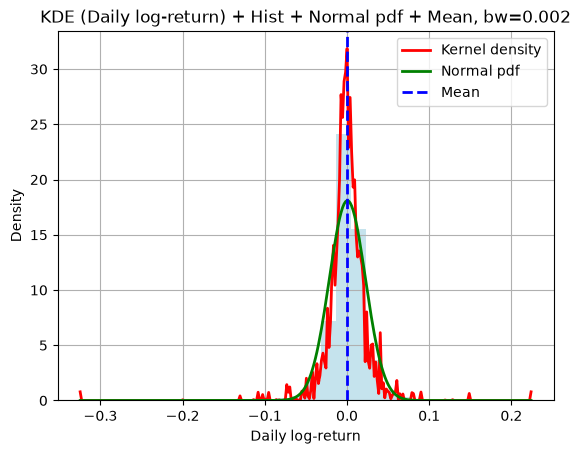

In [97]:
density_eval_points = np.linspace(rt_d.min(), rt_d.max(), num=300)
kde = gaussian_kde(rt_d, bw_method=0.002)
density_estimation = kde(density_eval_points)
pdf_theoretical = norm.pdf(density_eval_points, np.mean(rt_d), np.std(rt_d))
mean_data = np.mean(rt_d)

plt.hist(rt_d, bins=30, density=True, alpha=0.7, color='lightblue')
plt.plot(density_eval_points, density_estimation, color='red', lw=2, label='Kernel density')
plt.plot(density_eval_points, pdf_theoretical, color='green', lw=2, label='Normal pdf')
plt.axvline(mean_data, color='blue', linestyle='dashed', linewidth=2, label='Mean')
plt.xlabel("Daily log-return")
plt.ylabel("Density")
plt.title("KDE (Daily log-return) + Hist + Normal pdf + Mean, bw=0.002")
plt.legend()
plt.grid(True)
plt.show()

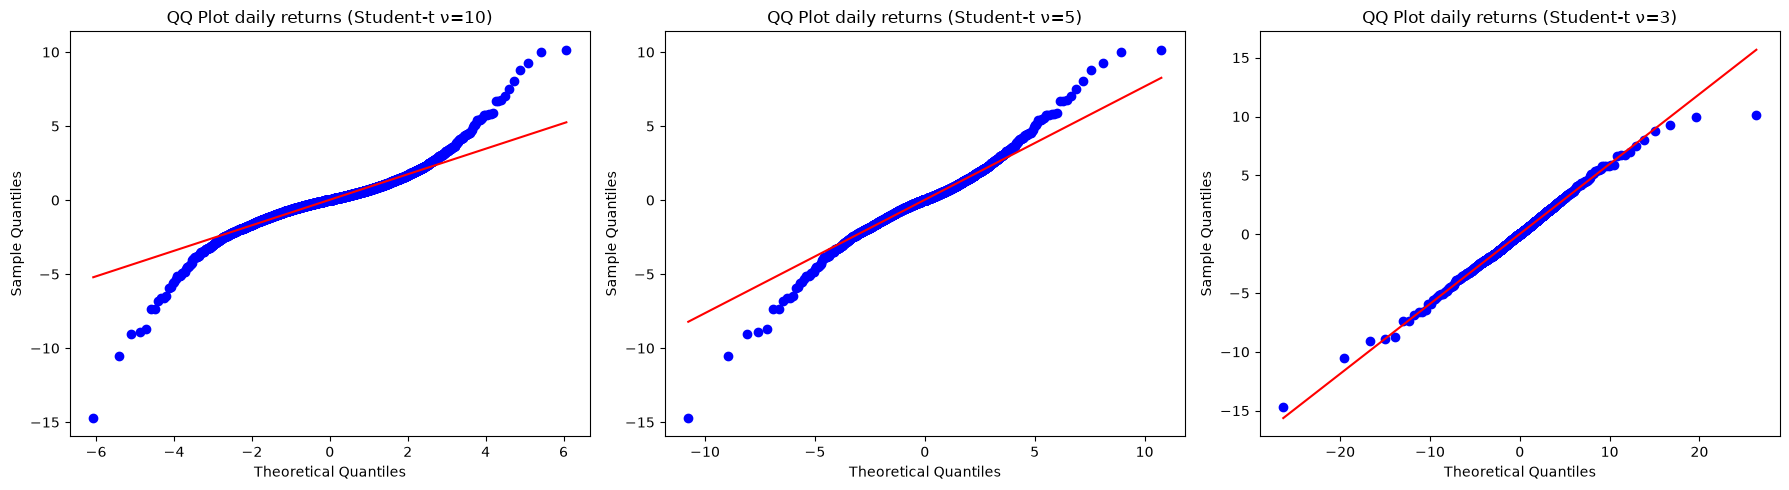

In [98]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

for ax, nu in zip(axs, [10, 5, 3]):
    stats.probplot(rt_d / np.std(rt_d), dist=stats.t(df=nu), plot=ax)
    ax.set_title(f'QQ Plot daily returns (Student-t ν={nu})')
    ax.set_xlabel('Theoretical Quantiles')
    ax.set_ylabel('Sample Quantiles')

plt.tight_layout()
plt.show()

**Test: one-sided test, H0: K = 3 vs H1: K > 3, with z = (K - 3) / sqrt(24/N) (asymptotic distribution of the sample kurtosis under normality). Reject H0 at 5% if z > 1.645.**

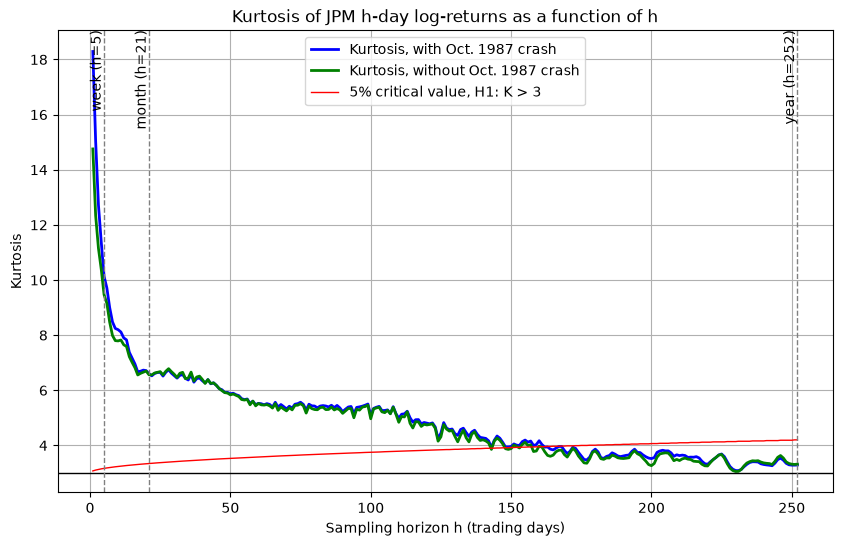

In [99]:
def kurtosis_by_horizon(log_prices, max_horizon=252):
    mean_kurtosis = {}
    for h in range(1, max_horizon + 1):
        mean_kurtosis[h] = np.mean([kurtosis(log_prices.iloc[start::h].diff().dropna()) + 3 for start in range(h)])
    return pd.Series(mean_kurtosis, name="Kurtosis")

kurtosis_horizon = kurtosis_by_horizon(pt_d)
kurtosis_horizon_noOct87crash = kurtosis_by_horizon(pt_d_noOct87crash)

horizons = kurtosis_horizon.index.values
N_horizon = (len(pt_d) - 1) // horizons
critical_line_kurtosis = 3 + 1.645 * np.sqrt(24 / N_horizon)

plt.figure(figsize=(10, 6))
plt.plot(horizons, kurtosis_horizon, color='blue', linewidth=2, label='Kurtosis, with Oct. 1987 crash')
plt.plot(horizons, kurtosis_horizon_noOct87crash, color='green', linewidth=2, label='Kurtosis, without Oct. 1987 crash')
plt.plot(horizons, critical_line_kurtosis, color='red', linewidth=1, label='5% critical value, H1: K > 3')
plt.axhline(3, color='black', linewidth=1)
for h, label in zip([5, 21, 252], ['week (h=5)', 'month (h=21)', 'year (h=252)']):
    plt.axvline(h, color='gray', linestyle='--', linewidth=1)
    plt.text(h, plt.ylim()[1], label, rotation=90, va='top', ha='right')
plt.xlabel('Sampling horizon h (trading days)')
plt.ylabel('Kurtosis')
plt.title('Kurtosis of JPM h-day log-returns as a function of h')
plt.legend()
plt.grid(True)
plt.show()

**Crossing horizon: first h at which the kurtosis is no longer significantly above 3 (z < 1.645), and last h at which it still is**

In [100]:
def crossing_horizons_kurtosis(kurtosis_curve, log_prices):
    N = (len(log_prices) - 1) // kurtosis_curve.index.values
    z = (kurtosis_curve.values - 3) / np.sqrt(24 / N)
    significant = z > 1.645
    return {"First h not significant": kurtosis_curve.index[~significant][0] if (~significant).any() else None,
            "Last h significant": kurtosis_curve.index[significant][-1] if significant.any() else None,
            "Number of h significant (out of 252)": int(significant.sum())}

pd.DataFrame({"with Oct. 1987 crash": crossing_horizons_kurtosis(kurtosis_horizon, pt_d),
              "without Oct. 1987 crash": crossing_horizons_kurtosis(kurtosis_horizon_noOct87crash, pt_d_noOct87crash)})

,with Oct. 1987 crash,without Oct. 1987 crash
First h not significant,162,143
Last h significant,161,160
Number of h significant (out of 252),161,153


**Table: kurtosis of JPM log-returns at daily, weekly, monthly and annual horizons, with and without the October 1987 crash, one-sided test H0: K = 3 vs H1: K > 3**

The critical kurtosis is 3 + 1.645 * sqrt(24/N), the smallest kurtosis that the test can detect at the 5% level for that sample size. The implied Student-t degrees of freedom are obtained by inverting the kurtosis of a Student-t, K = 3 + 6/(nu - 4), so nu = 4 + 6/(K - 3).

In [101]:
def implied_student_degrees_of_freedom(kurtosis_value):
    return 4 + 6 / (kurtosis_value - 3)


K_selected = kurtosis_horizon.loc[selected_horizons].values
K_selected_noOct87crash = kurtosis_horizon_noOct87crash.loc[selected_horizons].values
zK_selected = (K_selected - 3) / np.sqrt(24 / N_selected)
zK_selected_noOct87crash = (K_selected_noOct87crash - 3) / np.sqrt(24 / N_selected_noOct87crash)

pd.DataFrame({
    "h (trading days)": selected_horizons,
    "N": N_selected,
    "Critical kurtosis 5%": 3 + 1.645 * np.sqrt(24 / N_selected),
    "Kurtosis (with crash)": K_selected,
    "Student d.o.f. (with crash)": implied_student_degrees_of_freedom(K_selected),
    "z (with crash)": zK_selected,
    "p-value (with crash)": 1 - stats.norm.cdf(zK_selected),
    "Kurtosis (without crash)": K_selected_noOct87crash,
    "Student d.o.f. (without crash)": implied_student_degrees_of_freedom(K_selected_noOct87crash),
    "z (without crash)": zK_selected_noOct87crash,
    "p-value (without crash)": 1 - stats.norm.cdf(zK_selected_noOct87crash)
}, index=["daily", "weekly", "monthly", "annual"]).round(4)

,h (trading days),N,Critical kurtosis 5%,Kurtosis (with crash),Student d.o.f. (with crash),z (with crash),p-value (with crash),Kurtosis (without crash),Student d.o.f. (without crash),z (without crash),p-value (without crash)
daily,1,11542,3.0750,18.2899,4.3924,335.3043,0.0000,14.7554,4.5104,257.7374,0.0000
weekly,5,2308,3.1677,10.1362,4.8408,69.9804,0.0000,9.4687,4.9275,63.4217,0.0000
monthly,21,549,3.3439,6.6052,5.6642,17.2431,0.0000,6.5625,5.6842,17.0386,0.0000
annual,252,45,4.2013,3.2900,24.6920,0.3971,0.3457,3.3211,22.6831,0.4397,0.3301


**Table: tail index of daily log-returns.** The kurtosis-based estimate of the previous table uses the fourth moment, which is infinite when the degrees of freedom are below 4 and is driven by a handful of observations. Two estimators that use only the tails are added. The Hill estimator takes the $k$ largest observations of one tail, ordered $X_{(1)}\ge\dots\ge X_{(k)}$, and estimates the tail index as the inverse of $\frac{1}{k}\sum_{i=1}^{k}\ln\big(X_{(i)}/X_{(k+1)}\big)$; it is reported for three values of $k$ and separately for the two tails, which also tests the symmetry of stylized fact 3. The second estimator fits a Student-$t$ distribution to all the returns by maximum likelihood. For a Student-$t$ with $\nu$ degrees of freedom the tail index equals $\nu$, so the three estimates are comparable.

In [102]:
def tail_index_estimates(returns, tail_fractions=(0.01, 0.025, 0.05)):
    x = returns.values
    degrees_of_freedom_mle, location_mle, scale_mle = stats.t.fit(x)
    kurtosis_based = 4 + 6 / (kurtosis(x) + 3 - 3)
    table = {}
    for n_column, fraction in enumerate(tail_fractions):
        k = int(fraction * len(x))
        column = {}
        for name, sample in (("Hill tail index, left tail", np.sort(-x[x < 0])[::-1]),
                             ("Hill tail index, right tail", np.sort(x[x > 0])[::-1])):
            column[name] = round(1 / np.mean(np.log(sample[:k] / sample[k])), 3)
        column["Student-t d.o.f., maximum likelihood"] = round(degrees_of_freedom_mle, 3) if n_column == 0 else ""
        column["Student-t d.o.f., from the kurtosis"] = round(kurtosis_based, 3) if n_column == 0 else ""
        table[f"k = {k} ({fraction:.1%})"] = column
    return pd.DataFrame(table)


tail_index_estimates(rt_d)

,k = 115 (1.0%),k = 288 (2.5%),k = 577 (5.0%)
"Hill tail index, left tail",2.699,2.95,2.625
"Hill tail index, right tail",2.973,2.73,2.472
"Student-t d.o.f., maximum likelihood",2.822,,
"Student-t d.o.f., from the kurtosis",4.392,,


## Stylized fact 5: aggregational Gaussianity
See also the Kurtosis, Jarque-Bera and Lilliefors rows of the summary statistics table by frequency.

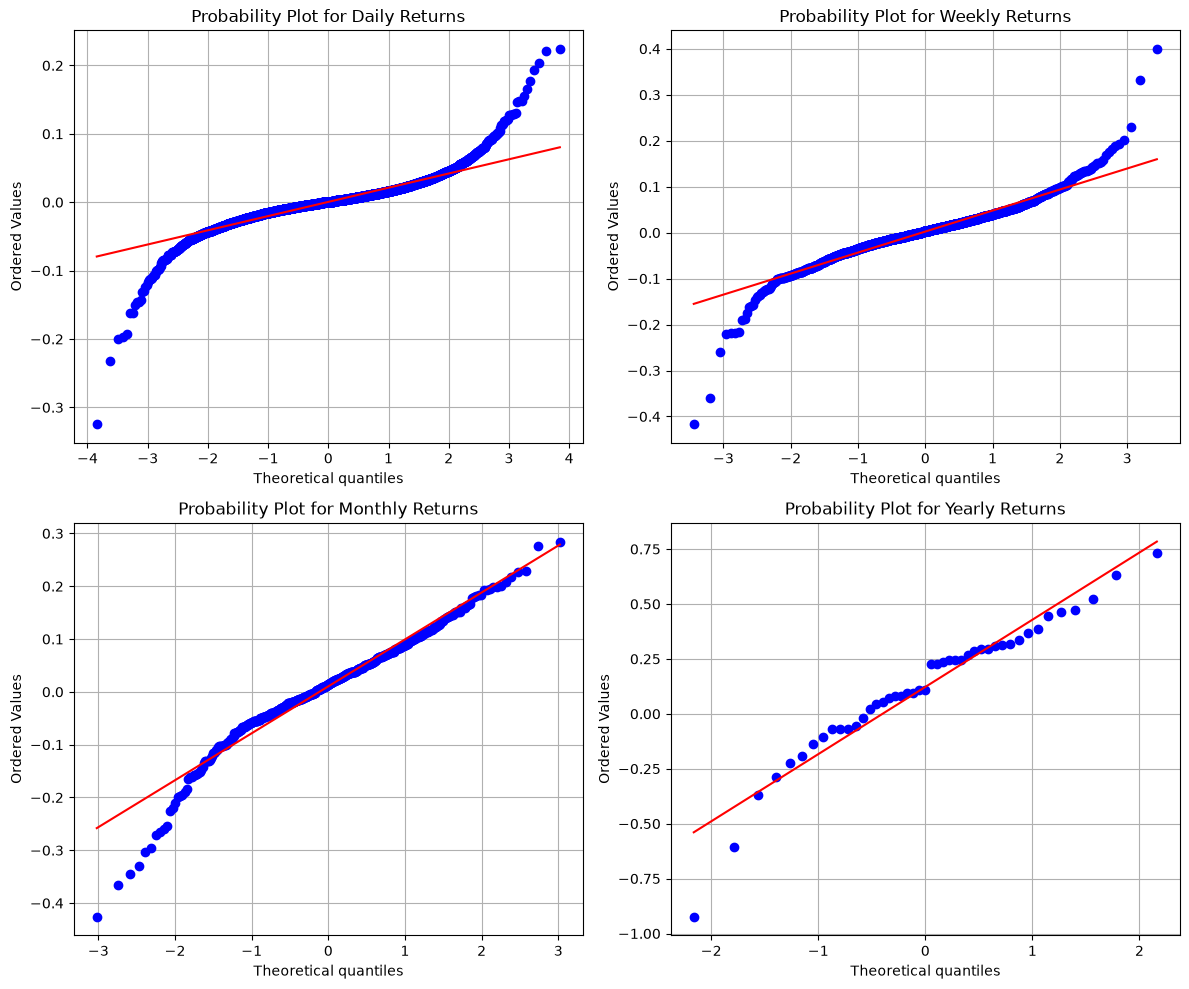

In [103]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

stats.probplot(rt_d, dist="norm", plot=axs[0, 0])
axs[0, 0].set_title("Probability Plot for Daily Returns")
axs[0, 0].grid(True)

stats.probplot(rt_w, dist="norm", plot=axs[0, 1])
axs[0, 1].set_title("Probability Plot for Weekly Returns")
axs[0, 1].grid(True)

stats.probplot(rt_m, dist="norm", plot=axs[1, 0])
axs[1, 0].set_title("Probability Plot for Monthly Returns")
axs[1, 0].grid(True)

stats.probplot(rt_y, dist="norm", plot=axs[1, 1])
axs[1, 1].set_title("Probability Plot for Yearly Returns")
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

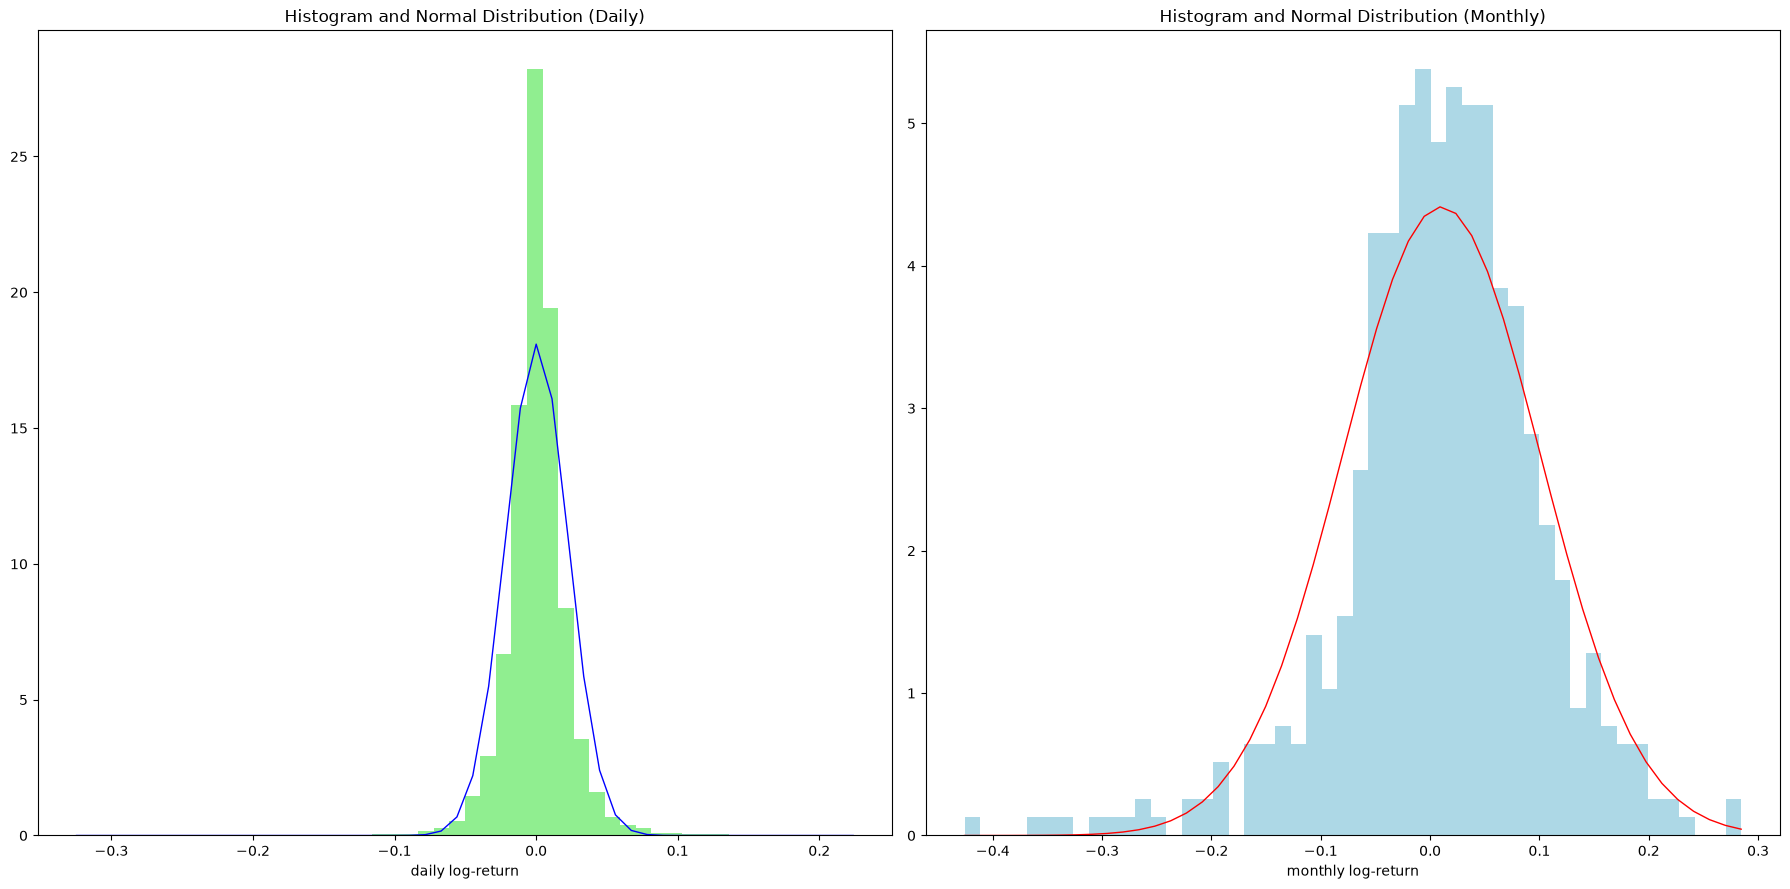

In [104]:
fig, axs = plt.subplots(1, 2, figsize=(18, 9))

axs[0].hist(rt_d, bins=50, density=True, color="lightgreen")
norm_y = stats.norm.pdf(np.linspace(rt_d.min(), rt_d.max()), loc=np.mean(rt_d), scale=np.std(rt_d))
axs[0].plot(np.linspace(rt_d.min(), rt_d.max()), norm_y, color="blue", linewidth=1)
axs[0].set_xlabel("daily log-return")
axs[0].set_title("Histogram and Normal Distribution (Daily)")

axs[1].hist(rt_m, bins=50, density=True, color="lightblue")
norm_y = stats.norm.pdf(np.linspace(rt_m.min(), rt_m.max()), loc=np.mean(rt_m), scale=np.std(rt_m))
axs[1].plot(np.linspace(rt_m.min(), rt_m.max()), norm_y, color="red", linewidth=1)
axs[1].set_xlabel("monthly log-return")
axs[1].set_title("Histogram and Normal Distribution (Monthly)")

plt.tight_layout()
plt.show()

**Table: normality tests of JPM log-returns by frequency (Jarque-Bera, Lilliefors, Anderson-Darling), H0: returns are normally distributed**

The Jarque-Bera statistic is proportional to the number of observations, which falls from 11542 to 45 across frequencies, so it cannot be compared across them. Jarque-Bera / N = (S^2 + (K-3)^2/4)/6 is a pure measure of shape and is comparable. The same convergence towards the normal distribution is visible in the implied Student-t degrees of freedom of stylized fact 4.

In [105]:
def normality_tests(x):
    ad = anderson(x, 'norm')
    return {
        'Jarque-Bera stat': jarque_bera(x)[0],
        'Jarque-Bera p-value': jarque_bera(x)[1],
        'Jarque-Bera / N': jarque_bera(x)[0] / len(x),
        'Lilliefors stat': lilliefors(x)[0],
        'Lilliefors p-value': lilliefors(x)[1],
        'Anderson-Darling stat': ad[0],
        'Anderson-Darling 5% critical value': ad[1][2],
        'Anderson-Darling reject H0 at 5%': ad[0] > ad[1][2]
    }

pd.DataFrame({key: normality_tests(data) for key, data in returns_by_frequency.items()}).round(4)

/var/folders/pn/r68g_5rj1dx_tb77j_j0dvx40000gn/T/ipykernel_21991/1840525933.py:2: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  ad = anderson(x, 'norm')


,daily,weekly,monthly,annual
Jarque-Bera stat,112450.454615,7739.003127,199.289176,13.746241
Jarque-Bera p-value,0.0,0.0,0.0,0.001035
Jarque-Bera / N,9.742718,3.239432,0.363004,0.305472
Lilliefors stat,0.084417,0.06628,0.067808,0.122569
Lilliefors p-value,0.001,0.001,0.001,0.090079
Anderson-Darling stat,212.922701,24.231698,4.123321,0.659303
Anderson-Darling 5% critical value,0.752,0.752,0.751,0.739
Anderson-Darling reject H0 at 5%,True,True,True,False


## Stylized fact 6: returns are not autocorrelated

In [106]:
def plot_autocorrelation_function_daily_weekly_monthly(daily, weekly, monthly, series_name, lags=40):
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    for ax, x, freq in zip(axs, [daily, weekly, monthly], ['Daily', 'Weekly', 'Monthly']):
        autocorrelation_function_values = acf(x, nlags=lags)
        confint = 1.96 / np.sqrt(len(x))
        ax.stem(np.arange(1, lags + 1), autocorrelation_function_values[1:], linefmt='k-', markerfmt='ko', basefmt='w-')
        ax.axhline(y=0, color='gray', linestyle='--')
        ax.plot(np.arange(1, lags + 1), np.full(lags, confint), color='blue', linestyle='dashed')
        ax.plot(np.arange(1, lags + 1), -np.full(lags, confint), color='blue', linestyle='dashed')
        ax.set_ylim(-0.1, 0.3)
        ax.set_title(f'Autocorrelation function - {freq} {series_name}')
        ax.set_xlabel('Lag')
        ax.set_ylabel('Autocorrelation function')
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def autocorrelation_function_box_pierce_ljung_box_table(x, max_lag):
    lags_all = np.arange(1, max_lag + 1)
    my_autocorrelation_function = sm.tsa.acf(x, nlags=max_lag)
    my_autocorrelation_function_diameter = 1.96 / np.sqrt(len(x))
    my_autocorrelation_function_tstat_0 = (my_autocorrelation_function[1:] - 0) / np.sqrt(1 / len(x))
    my_LjungBox = sm.stats.diagnostic.acorr_ljungbox(x, lags=lags_all, boxpierce=False)
    my_BoxPierce = sm.stats.diagnostic.acorr_ljungbox(x, lags=lags_all, boxpierce=True)
    crit_value_5_BP = stats.chi2.ppf(0.95, lags_all)
    my_table = np.column_stack((
        lags_all,
        my_autocorrelation_function[1:],
        np.full(max_lag, my_autocorrelation_function_diameter),
        my_autocorrelation_function_tstat_0,
        my_BoxPierce['bp_stat'],
        my_BoxPierce['bp_pvalue'],
        my_LjungBox['lb_stat'],
        my_LjungBox['lb_pvalue'],
        crit_value_5_BP
    ))
    column_names = ["lag", "autocorrelation function", "autocorrelation function diam.", "autocorrelation function test", "B-P stat", "B-P pval", "L-B stat", "L-B pval", "crit"]
    return pd.DataFrame(data=my_table, columns=column_names).round(3)

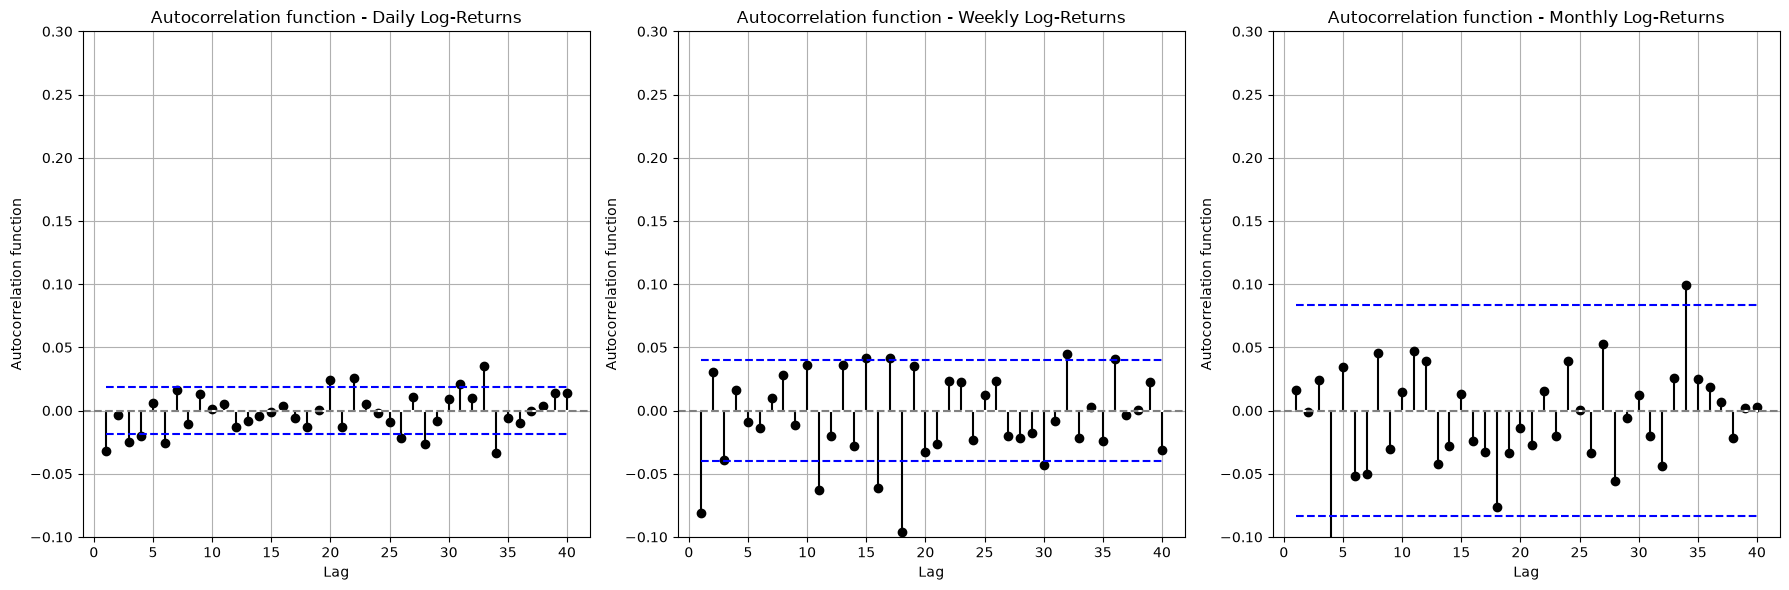

In [107]:
plot_autocorrelation_function_daily_weekly_monthly(rt_d, rt_w, rt_m, 'Log-Returns')

**Autocorrelation function of annual log-returns (10 lags, about 45 observations)**

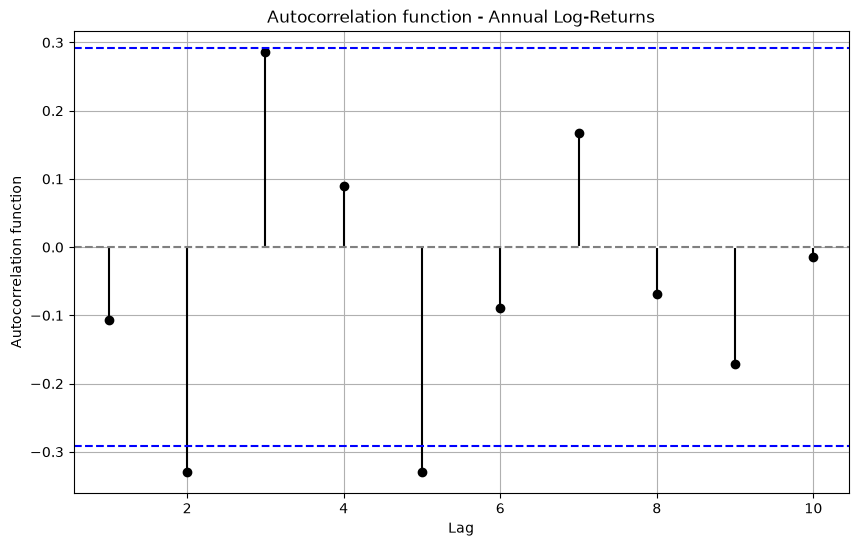

In [108]:
plot_autocorrelation_function_with_bartlett_bands(rt_y, 'Autocorrelation function - Annual Log-Returns', lags=10)

**Table: autocorrelation function, Box-Pierce and Ljung-Box tests – daily log-returns (lags 1 to 25)**

In [109]:
autocorrelation_function_box_pierce_ljung_box_table(rt_d, 25)

,lag,autocorrelation function,autocorrelation function diam.,autocorrelation function test,B-P stat,B-P pval,L-B stat,L-B pval,crit
0,1.0,-0.032,0.018,-3.472,12.052,0.001,12.055,0.001,3.841
1,2.0,-0.003,0.018,-0.368,12.187,0.002,12.191,0.002,5.991
2,3.0,-0.025,0.018,-2.713,19.548,0.000,19.555,0.000,7.815
3,4.0,-0.020,0.018,-2.156,24.196,0.000,24.204,0.000,9.488
4,5.0,0.006,0.018,0.646,24.613,0.000,24.622,0.000,11.070
5,6.0,-0.026,0.018,-2.801,32.459,0.000,32.474,0.000,12.592
6,7.0,0.016,0.018,1.756,35.541,0.000,35.558,0.000,14.067
7,8.0,-0.011,0.018,-1.151,36.866,0.000,36.884,0.000,15.507
8,9.0,0.013,0.018,1.399,38.822,0.000,38.842,0.000,16.919
9,10.0,0.001,0.018,0.097,38.832,0.000,38.852,0.000,18.307


**Table: autocorrelation function, Box-Pierce and Ljung-Box tests – weekly log-returns (lags 1 to 25)**

In [110]:
autocorrelation_function_box_pierce_ljung_box_table(rt_w, 25)

,lag,autocorrelation function,autocorrelation function diam.,autocorrelation function test,B-P stat,B-P pval,L-B stat,L-B pval,crit
0,1.0,-0.081,0.04,-3.950,15.604,0.000,15.624,0.000,3.841
1,2.0,0.031,0.04,1.506,17.871,0.000,17.895,0.000,5.991
2,3.0,-0.039,0.04,-1.897,21.472,0.000,21.503,0.000,7.815
3,4.0,0.016,0.04,0.786,22.089,0.000,22.121,0.000,9.488
4,5.0,-0.009,0.04,-0.456,22.296,0.000,22.329,0.000,11.070
5,6.0,-0.014,0.04,-0.669,22.744,0.001,22.778,0.001,12.592
6,7.0,0.010,0.04,0.477,22.971,0.002,23.007,0.002,14.067
7,8.0,0.028,0.04,1.384,24.886,0.002,24.930,0.002,15.507
8,9.0,-0.012,0.04,-0.570,25.211,0.003,25.256,0.003,16.919
9,10.0,0.036,0.04,1.750,28.273,0.002,28.333,0.002,18.307


**Table: autocorrelation function, Box-Pierce and Ljung-Box tests – monthly log-returns (lags 1 to 25)**

In [111]:
autocorrelation_function_box_pierce_ljung_box_table(rt_m, 25)

,lag,autocorrelation function,autocorrelation function diam.,autocorrelation function test,B-P stat,B-P pval,L-B stat,L-B pval,crit
0,1.0,0.017,0.084,0.389,0.151,0.697,0.152,0.696,3.841
1,2.0,-0.001,0.084,-0.026,0.152,0.927,0.153,0.926,5.991
2,3.0,0.024,0.084,0.568,0.474,0.925,0.478,0.924,7.815
3,4.0,-0.170,0.084,-3.972,16.252,0.003,16.429,0.002,9.488
4,5.0,0.035,0.084,0.815,16.916,0.005,17.102,0.004,11.070
5,6.0,-0.052,0.084,-1.213,18.389,0.005,18.596,0.005,12.592
6,7.0,-0.050,0.084,-1.170,19.756,0.006,19.987,0.006,14.067
7,8.0,0.045,0.084,1.064,20.888,0.007,21.139,0.007,15.507
8,9.0,-0.031,0.084,-0.722,21.409,0.011,21.671,0.010,16.919
9,10.0,0.014,0.084,0.336,21.522,0.018,21.786,0.016,18.307


**Table: autocorrelation function, Box-Pierce and Ljung-Box tests – annual log-returns (lags 1 to 10)**

In [112]:
autocorrelation_function_box_pierce_ljung_box_table(rt_y, 10)

,lag,autocorrelation function,autocorrelation function diam.,autocorrelation function test,B-P stat,B-P pval,L-B stat,L-B pval,crit
0,1.0,-0.106,0.292,-0.713,0.508,0.476,0.543,0.461,3.841
1,2.0,-0.329,0.292,-2.208,5.385,0.068,5.874,0.053,5.991
2,3.0,0.286,0.292,1.919,9.069,0.028,9.996,0.019,7.815
3,4.0,0.090,0.292,0.601,9.430,0.051,10.410,0.034,9.488
4,5.0,-0.330,0.292,-2.211,14.317,0.014,16.152,0.006,11.070
5,6.0,-0.089,0.292,-0.596,14.673,0.023,16.580,0.011,12.592
6,7.0,0.167,0.292,1.118,15.923,0.026,18.127,0.011,14.067
7,8.0,-0.069,0.292,-0.460,16.135,0.040,18.396,0.018,15.507
8,9.0,-0.172,0.292,-1.151,17.460,0.042,20.127,0.017,16.919
9,10.0,-0.014,0.292,-0.093,17.469,0.065,20.139,0.028,18.307


**Regression of returns on their own lags with White's heteroskedasticity-consistent standard errors (Lecture 2), and global F-test H0: all lag coefficients = 0.** The Ljung-Box and Bartlett bands above assume i.i.d. returns under H0, which fixes the variance of the sample autocorrelation at 1/N. Under the conditional heteroskedasticity of stylized fact 7 that variance is understated, so the test over-rejects. The White standard errors do not require homoskedasticity. The first rows of the tables are t-statistics.

In [113]:
def autoregression_with_white_standard_errors(returns, n_lags=5):
    y = returns.iloc[n_lags:]
    X = pd.DataFrame({f"r(t-{lag})": returns.shift(lag).iloc[n_lags:] for lag in range(1, n_lags + 1)})
    X.insert(0, "const", 1.0)
    model = sm.OLS(y, X).fit()
    model_white = model.get_robustcov_results(cov_type='HC0')
    restriction = np.eye(n_lags + 1)[1:]
    table = pd.DataFrame({"Coefficient": model.params.values,
                          "OLS": model.tvalues.values,
                          "White": model_white.tvalues}, index=X.columns)
    table.loc["F-stat (H0: all lags = 0)"] = ["",
                                              float(np.squeeze(model.f_test(restriction).fvalue)),
                                              float(np.squeeze(model_white.f_test(restriction).fvalue))]
    table.loc["p-value"] = ["",
                            float(np.squeeze(model.f_test(restriction).pvalue)),
                            float(np.squeeze(model_white.f_test(restriction).pvalue))]
    table.loc["R-squared"] = ["", model.rsquared, model.rsquared]
    return table.round(4)

**Table: regression of daily log-returns on 5 lags, OLS vs. White t-statistics**

In [114]:
autoregression_with_white_standard_errors(rt_d, 5)

,Coefficient,OLS,White
const,0.000536,2.6120,2.5401
r(t-1),-0.032913,-3.5344,-1.5282
r(t-2),-0.005379,-0.5775,-0.2740
r(t-3),-0.026189,-2.8125,-1.4323
r(t-4),-0.02159,-2.3179,-1.1633
r(t-5),0.004431,0.4758,0.2369
F-stat (H0: all lags = 0),,5.0809,0.9842
p-value,,0.0001,0.4257
R-squared,,0.0022,0.0022


**Table: regression of weekly log-returns on 5 lags, OLS vs. White t-statistics**

In [115]:
autoregression_with_white_standard_errors(rt_w, 5)

,Coefficient,OLS,White
const,0.002593,2.6567,2.4634
r(t-1),-0.077074,-3.7585,-1.7762
r(t-2),0.022042,1.0718,0.6694
r(t-3),-0.033834,-1.6458,-0.9757
r(t-4),0.009114,0.4435,0.3167
r(t-5),-0.005452,-0.2661,-0.2094
F-stat (H0: all lags = 0),,4.0281,0.9306
p-value,,0.0012,0.4599
R-squared,,0.0084,0.0084


**Table: regression of monthly log-returns on 5 lags, OLS vs. White t-statistics**

In [116]:
autoregression_with_white_standard_errors(rt_m, 5)

,Coefficient,OLS,White
const,0.010996,2.7679,2.5049
r(t-1),0.027549,0.6396,0.4684
r(t-2),-0.003681,-0.0867,-0.0645
r(t-3),0.027321,0.6439,0.5968
r(t-4),-0.171216,-4.0348,-3.5723
r(t-5),0.04245,0.9860,0.8806
F-stat (H0: all lags = 0),,3.5141,2.6158
p-value,,0.0039,0.0238
R-squared,,0.0316,0.0316


## Stylized fact 7: volatility clustering and long range dependence of squared returns

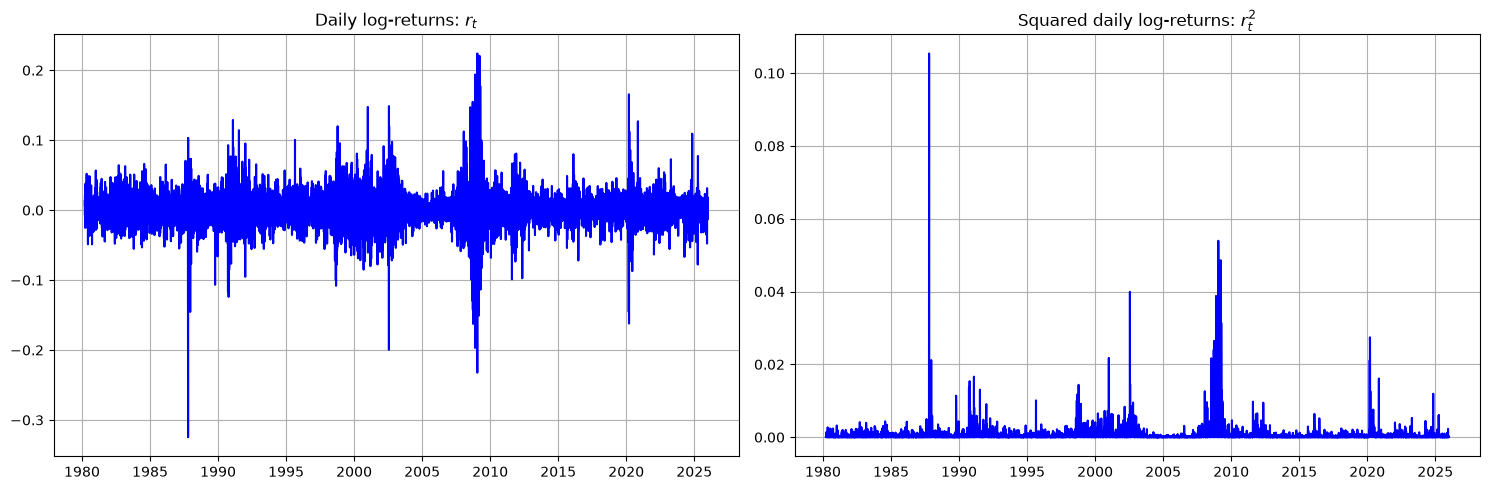

In [117]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].plot(rt_d.index, rt_d, color='blue')
axs[0].set_title('Daily log-returns: $r_t$')
axs[0].grid(True)
axs[1].plot(rt_d.index, rt_d**2, color='blue')
axs[1].set_title('Squared daily log-returns: $r_t^2$')
axs[1].grid(True)
plt.tight_layout()
plt.show()

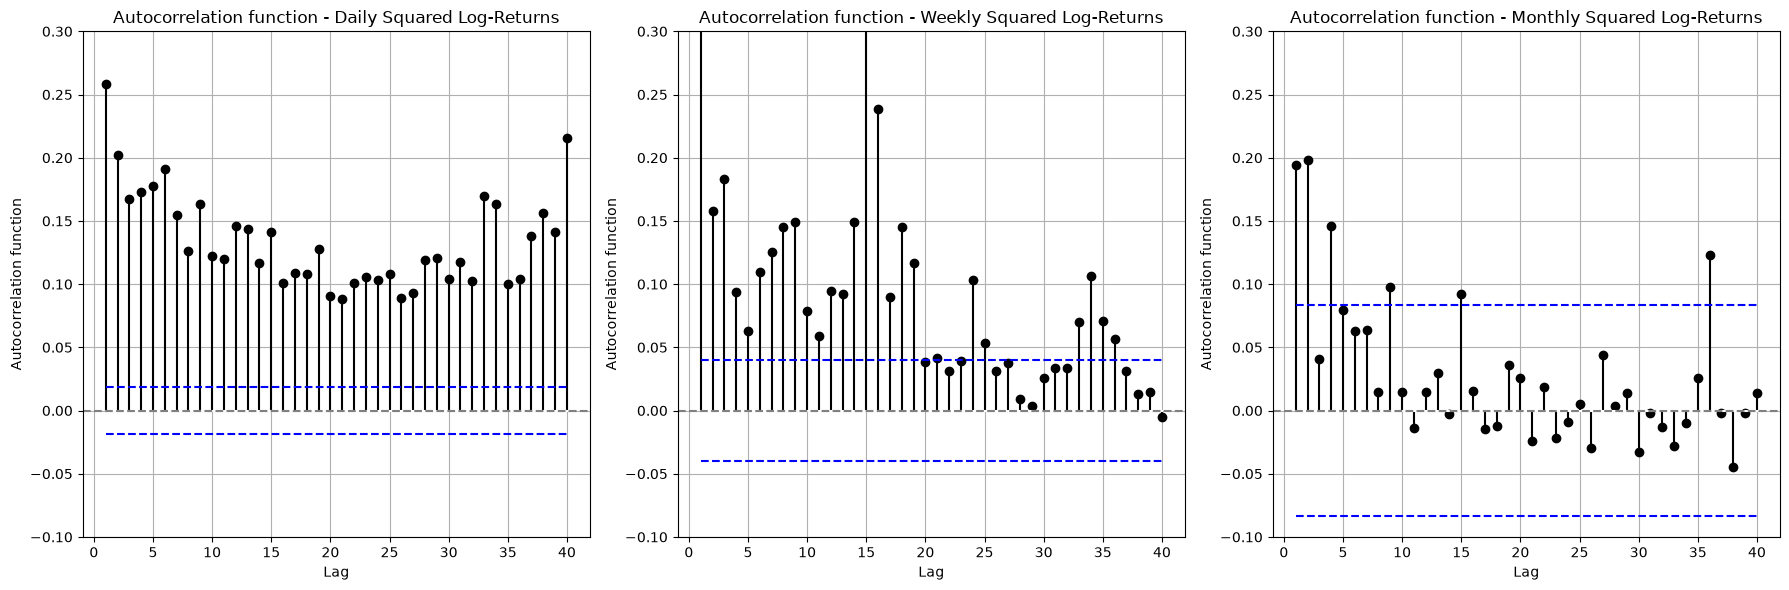

In [118]:
plot_autocorrelation_function_daily_weekly_monthly(rt_d**2, rt_w**2, rt_m**2, 'Squared Log-Returns')

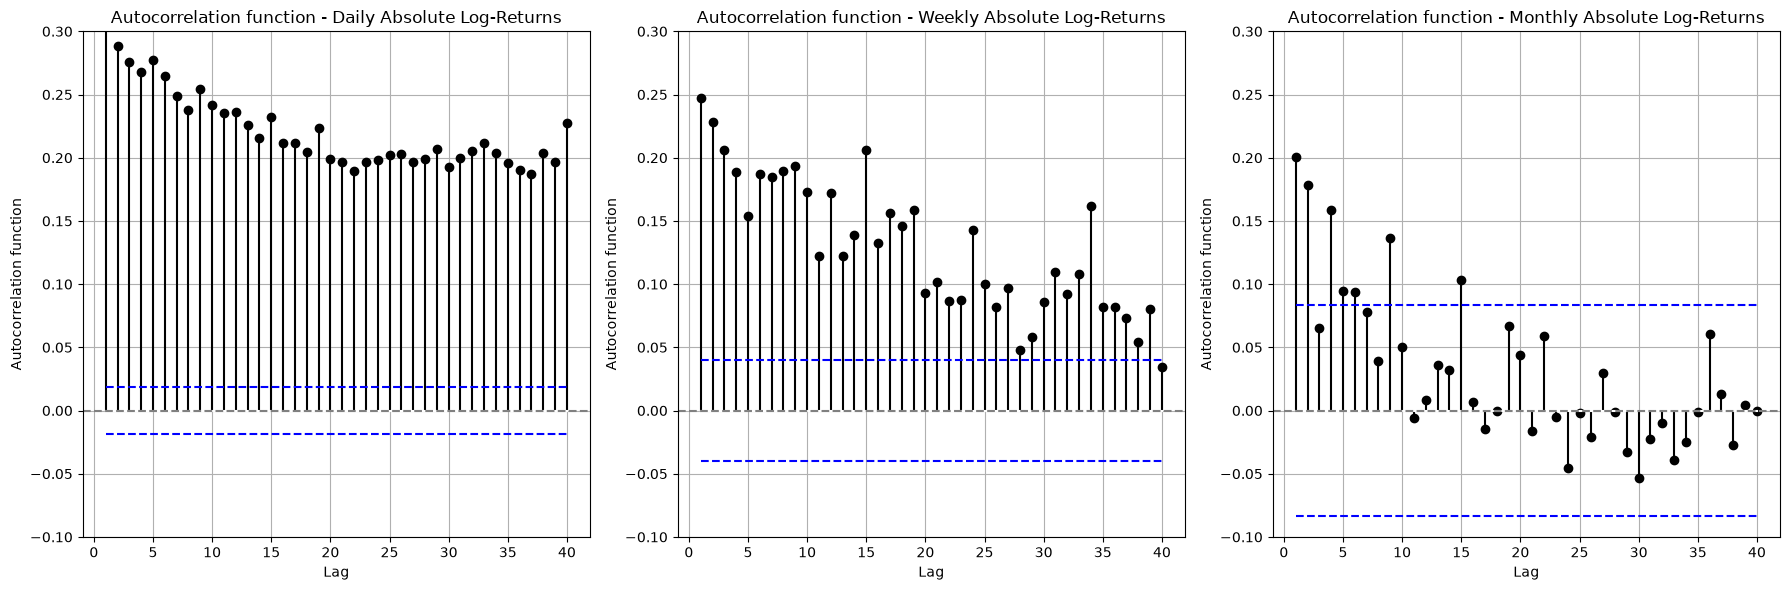

In [119]:
plot_autocorrelation_function_daily_weekly_monthly(abs(rt_d), abs(rt_w), abs(rt_m), 'Absolute Log-Returns')

**Table: autocorrelation function, Box-Pierce and Ljung-Box tests – squared daily log-returns (lags 1 to 25)**

In [120]:
autocorrelation_function_box_pierce_ljung_box_table(rt_d**2, 25)

,lag,autocorrelation function,autocorrelation function diam.,autocorrelation function test,B-P stat,B-P pval,L-B stat,L-B pval,crit
0,1.0,0.258,0.018,27.753,770.220,0.0,770.420,0.0,3.841
1,2.0,0.202,0.018,21.715,1241.757,0.0,1242.121,0.0,5.991
2,3.0,0.167,0.018,17.974,1564.816,0.0,1565.319,0.0,7.815
3,4.0,0.173,0.018,18.557,1909.180,0.0,1909.862,0.0,9.488
4,5.0,0.178,0.018,19.079,2273.187,0.0,2274.090,0.0,11.070
5,6.0,0.191,0.018,20.488,2692.944,0.0,2694.138,0.0,12.592
6,7.0,0.155,0.018,16.618,2969.095,0.0,2970.505,0.0,14.067
7,8.0,0.126,0.018,13.531,3152.190,0.0,3153.759,0.0,15.507
8,9.0,0.163,0.018,17.551,3460.240,0.0,3462.102,0.0,16.919
9,10.0,0.122,0.018,13.099,3631.835,0.0,3633.876,0.0,18.307


**Table: Engle's ARCH test on daily log-returns**, $H_0$: no conditional heteroskedasticity. The squared returns are regressed on $m$ of their own lags and the test statistic is $N R^2 \sim \chi^2(m)$ under $H_0$. Unlike the Ljung-Box test above, it is explicitly a test of an ARCH structure in the variance.

In [121]:
def arch_lagrange_multiplier_test(returns, lags=(1, 5, 10, 25)):
    table = {}
    for n_lags in lags:
        statistic, p_value, f_statistic, f_p_value = het_arch(returns, nlags=n_lags)
        table[f"{n_lags} lags"] = {"LM stat": statistic,
                                   "Critical value 5%": stats.chi2.ppf(0.95, n_lags),
                                   "p-value": p_value}
    return pd.DataFrame(table).round(4)


arch_lagrange_multiplier_test(rt_d)

,1 lags,5 lags,10 lags,25 lags
LM stat,770.1596,1280.4485,1463.9518,1581.2311
Critical value 5%,3.8415,11.0705,18.3070,37.6525
p-value,0.0000,0.0000,0.0000,0.0000


**Table: autocorrelation function of squared log-returns at daily, weekly and monthly frequency (slide 134: the autocorrelations become weaker and less persistent when the sampling interval increases)**

In [122]:
autocorrelation_function_table({"daily squared": rt_d**2, "weekly squared": rt_w**2,
                                "monthly squared": rt_m**2}, lags=(1, 5, 10, 20, 40))

,daily squared,weekly squared,monthly squared
lag 1,0.2583,0.3783,0.1945
lag 5,0.1776,0.0630,0.0797
lag 10,0.1219,0.0786,0.0147
lag 20,0.0908,0.0382,0.0255
lag 40,0.2155,-0.0048,0.0141
Bartlett diam.,0.0182,0.0401,0.0837


**Table: autocorrelation function of squared daily log-returns by sub-period (slide 135: the stylized fact holds for every sub-period of the dataset)**

In [123]:
autocorrelation_function_table({f"{x.index[0].year}-{x.index[-1].year}": x**2 for x in sub_periods},
                               lags=(1, 5, 20, 60))

,1980-1991,1991-2003,2003-2014,2014-2025
lag 1,0.0480,0.2450,0.3527,0.4268
lag 5,0.0737,0.1246,0.2266,0.2897
lag 20,0.0099,0.0574,0.1381,0.0842
lag 60,0.0046,0.0335,0.0906,0.0371
Bartlett diam.,0.0365,0.0365,0.0365,0.0365


**GARCH(1,1) model of the conditional variance**, $h_t=\omega+\alpha r_{t-1}^2+\beta h_{t-1}$, estimated by maximum likelihood on daily log-returns (the likelihood is written and maximised directly, no external package is used). The model formalises the clustering: a large return raises tomorrow's variance through $\alpha$, and the effect dies out at rate $\alpha+\beta$. If the model captures the clustering, the standardized residuals $z_t=(r_t-\bar r)/\sqrt{h_t}$ should show none: the Ljung-Box statistic on $z_t^2$ is therefore the test of interest, next to the same statistic on $r_t^2$.

In [124]:
def fit_garch_11(returns):
    x = (returns - returns.mean()).values * 100
    unconditional_variance = np.var(x)

    def conditional_variances(omega, alpha, beta):
        h = np.empty(len(x))
        h[0] = unconditional_variance
        for t in range(1, len(x)):
            h[t] = omega + alpha * x[t - 1]**2 + beta * h[t - 1]
        return h

    def negative_log_likelihood(parameters):
        omega, alpha, beta = parameters
        if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 0.9999:
            return 1e12
        h = conditional_variances(omega, alpha, beta)
        return 0.5 * np.sum(np.log(h) + x**2 / h)

    estimate = minimize(negative_log_likelihood,
                        x0=[0.05 * unconditional_variance, 0.08, 0.90],
                        method="Nelder-Mead",
                        options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 5000, "maxfev": 5000})
    omega, alpha, beta = estimate.x
    volatility = pd.Series(np.sqrt(conditional_variances(omega, alpha, beta)) / 100, index=returns.index)
    standardized_residuals = (returns - returns.mean()) / volatility
    return {"omega": omega, "alpha": alpha, "beta": beta,
            "volatility": volatility, "standardized_residuals": standardized_residuals}


garch = fit_garch_11(rt_d)
persistence = garch["alpha"] + garch["beta"]
z = garch["standardized_residuals"]

pd.Series({"omega (x 10^4, in %^2)": garch["omega"] * 10000,
           "alpha": garch["alpha"],
           "beta": garch["beta"],
           "alpha + beta (persistence)": persistence,
           "Half-life of a shock (days)": np.log(0.5) / np.log(persistence),
           "Unconditional st.dev. implied (%)": np.sqrt(garch["omega"] / (1 - persistence)),
           "Unconditional st.dev. in the sample (%)": rt_d.std() * 100,
           "Ljung-Box(25) on squared returns": acorr_ljungbox(rt_d**2, lags=[25])["lb_stat"].iloc[0],
           "p-value": acorr_ljungbox(rt_d**2, lags=[25])["lb_pvalue"].iloc[0],
           "Ljung-Box(25) on squared standardized residuals": acorr_ljungbox(z**2, lags=[25])["lb_stat"].iloc[0],
           "p-value ": acorr_ljungbox(z**2, lags=[25])["lb_pvalue"].iloc[0],
           "Kurtosis of standardized residuals": kurtosis(z) + 3}).round(4)

omega (x 10^4, in %^2)                              458.8750
alpha                                                 0.0831
beta                                                  0.9094
alpha + beta (persistence)                            0.9926
Half-life of a shock (days)                          92.7547
Unconditional st.dev. implied (%)                     2.4826
Unconditional st.dev. in the sample (%)               2.2048
Ljung-Box(25) on squared returns                   5939.1827
p-value                                               0.0000
Ljung-Box(25) on squared standardized residuals      25.6593
p-value                                               0.4260
Kurtosis of standardized residuals                   10.1909
dtype: float64

**Estimated conditional volatility $\sqrt{h_t}$ of daily log-returns (GARCH(1,1))**

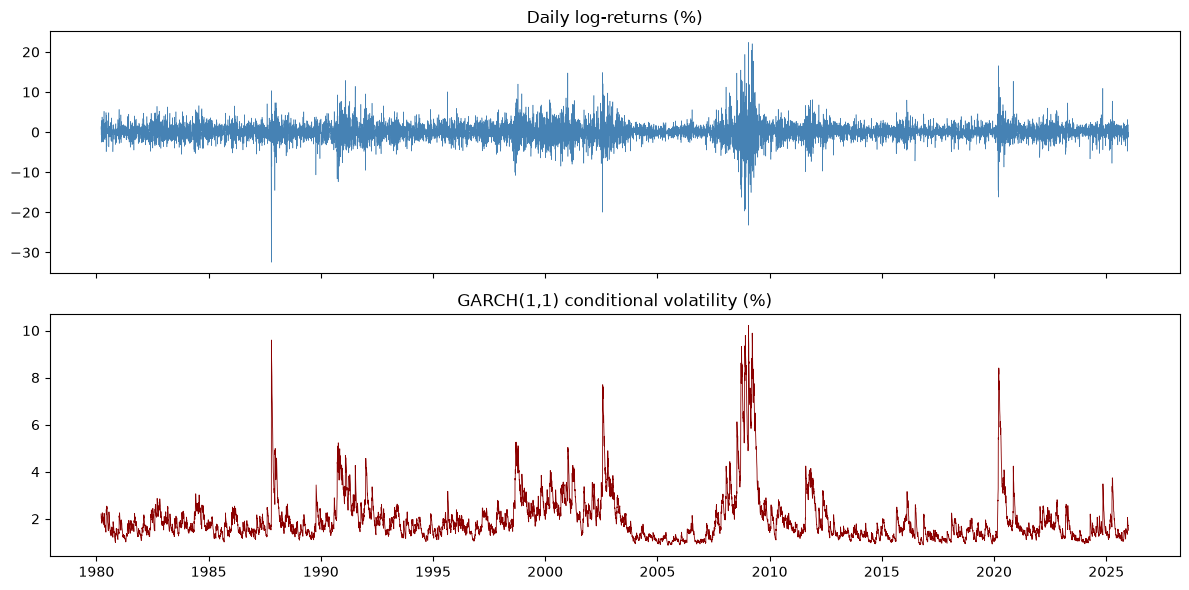

In [125]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axs[0].plot(rt_d.index, rt_d * 100, linewidth=0.4, color="steelblue")
axs[0].set_title("Daily log-returns (%)")
axs[1].plot(garch["volatility"].index, garch["volatility"] * 100, linewidth=0.6, color="darkred")
axs[1].set_title("GARCH(1,1) conditional volatility (%)")
plt.tight_layout()
plt.show()

## Stylized fact 8: leverage effect

In [126]:
def cross_correlation(x, y, lag_max=100):
    result = ss.correlate(y - np.mean(y), x - np.mean(x), method='direct') / (np.std(y) * np.std(x) * len(y))
    length = (len(result) - 1) // 2
    lo = length - lag_max
    hi = length + (lag_max + 1)
    return result[lo:hi]

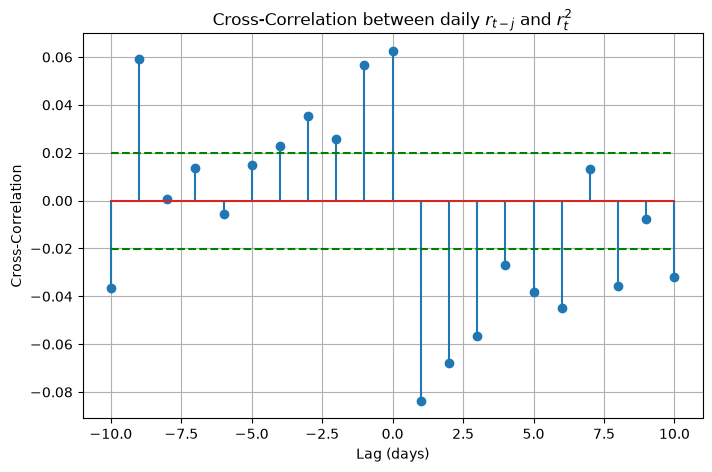

In [127]:
rt_d_post87 = rt_d.loc[pd.to_datetime('1988-01-01'):]

lag_max = 10
cross_corr = cross_correlation(rt_d_post87, rt_d_post87**2, lag_max=lag_max)
lags = np.arange(-lag_max, lag_max + 1)
confint_daily = 1.96 / np.sqrt(len(rt_d_post87))

plt.figure(figsize=(8, 5))
plt.stem(lags, cross_corr)
plt.plot(lags, np.full(len(lags), confint_daily), color='green', linestyle='dashed')
plt.plot(lags, -np.full(len(lags), confint_daily), color='green', linestyle='dashed')
plt.xlabel('Lag (days)')
plt.ylabel('Cross-Correlation')
plt.title('Cross-Correlation between daily $r_{t-j}$ and $r_t^2$')
plt.grid(True)
plt.show()

**Table: cross-correlations corr(r_{t-j}, r_t^2), daily log-returns 1988-2025, with z = rho * sqrt(N). For j > 0 one-sided test H1: rho < 0 (leverage effect), for j <= 0 two-sided test**

In [128]:
def cross_correlation_table(returns, lag_max=10):
    rho = cross_correlation(returns, returns**2, lag_max=lag_max)
    lags = np.arange(-lag_max, lag_max + 1)
    N = len(returns)
    z = rho * np.sqrt(N)
    p_value = np.where(lags > 0, stats.norm.cdf(z), 2 * (1 - stats.norm.cdf(np.abs(z))))
    return pd.DataFrame({"j": lags, "Cross-correlation": rho, "z": z, "p-value": p_value}).set_index("j").round(4)


def cross_correlation_joint_test(returns, lag_max=10):
    rho = cross_correlation(returns, returns**2, lag_max=lag_max)[lag_max + 1:]
    Q = len(returns) * np.sum(rho**2)
    return pd.Series({"Q = N * sum rho(j)^2, j = 1..10": Q,
                      "df": lag_max,
                      "Critical value 5%": stats.chi2.ppf(0.95, lag_max),
                      "p-value": stats.chi2.sf(Q, lag_max)}).round(4)

cross_correlation_table(rt_d_post87)

,Cross-correlation,z,p-value
j,,,
-10,-0.0363,-3.5543,0.0004
-9,0.0590,5.7698,0.0000
-8,0.0005,0.0505,0.9597
-7,0.0134,1.3131,0.1891
-6,-0.0055,-0.5377,0.5908
-5,0.0151,1.4732,0.1407
-4,0.0230,2.2505,0.0244
-3,0.0355,3.4748,0.0005
-2,0.0259,2.5342,0.0113


**Joint test: H0: corr(r_{t-j}, r_t^2) = 0 for j = 1, ..., 10 – daily log-returns 1988-2025**

In [129]:
cross_correlation_joint_test(rt_d_post87)

Q = N * sum rho(j)^2, j = 1..10    206.5046
df                                  10.0000
Critical value 5%                   18.3070
p-value                              0.0000
dtype: float64

**Regression of squared returns on the lagged returns with White's heteroskedasticity-consistent standard errors (Lecture 2), and global F-test H0: all lag coefficients = 0.** The cross-correlation test above uses z = rho * sqrt(N), which assumes i.i.d. returns. The cross-correlations at negative lags, where no leverage effect can exist, are also significant under that rule, which shows it is not correctly calibrated here. The first rows of the tables are t-statistics.

In [130]:
def leverage_regression_with_white_standard_errors(returns, n_lags=10):
    y = (returns**2).iloc[n_lags:]
    X = pd.DataFrame({f"r(t-{lag})": returns.shift(lag).iloc[n_lags:] for lag in range(1, n_lags + 1)})
    X.insert(0, "const", 1.0)
    model = sm.OLS(y, X).fit()
    model_white = model.get_robustcov_results(cov_type='HC0')
    restriction = np.eye(n_lags + 1)[1:]
    table = pd.DataFrame({"Coefficient": model.params.values,
                          "OLS": model.tvalues.values,
                          "White": model_white.tvalues}, index=X.columns)
    table.loc["F-stat (H0: all lags = 0)"] = ["",
                                              float(np.squeeze(model.f_test(restriction).fvalue)),
                                              float(np.squeeze(model_white.f_test(restriction).fvalue))]
    table.loc["p-value"] = ["",
                            float(np.squeeze(model.f_test(restriction).pvalue)),
                            float(np.squeeze(model_white.f_test(restriction).pvalue))]
    table.loc["R-squared"] = ["", model.rsquared, model.rsquared]
    return table.round(4)

**Table: regression of squared daily log-returns on 10 lagged returns, 1988-2025 sample, OLS vs. White t-statistics**

In [131]:
leverage_regression_with_white_standard_errors(rt_d_post87, 10)

,Coefficient,OLS,White
const,0.00053,27.3902,23.6386
r(t-1),-0.007456,-8.7040,-2.1158
r(t-2),-0.006607,-7.7054,-2.3937
r(t-3),-0.005257,-6.1312,-1.9972
r(t-4),-0.003055,-3.5624,-1.1424
r(t-5),-0.004035,-4.7070,-1.8357
r(t-6),-0.00431,-5.0313,-1.5658
r(t-7),0.000352,0.4104,0.1419
r(t-8),-0.00325,-3.7938,-1.6049
r(t-9),-0.001215,-1.4190,-0.4458


**Table: regression of squared daily log-returns on 10 lagged returns, full sample with the 1987 crash, OLS vs. White t-statistics**

In [132]:
leverage_regression_with_white_standard_errors(rt_d, 10)

,Coefficient,OLS,White
const,0.000504,26.9401,23.7972
r(t-1),-0.007502,-8.8528,-2.3528
r(t-2),-0.006079,-7.1696,-2.4993
r(t-3),-0.004969,-5.8605,-2.1399
r(t-4),-0.002099,-2.4755,-0.8827
r(t-5),-0.003764,-4.4385,-1.9274
r(t-6),-0.003937,-4.6430,-1.6497
r(t-7),0.000057,0.0674,0.0263
r(t-8),-0.003037,-3.5827,-1.7156
r(t-9),-0.001449,-1.7097,-0.5989


**Sensitivity to the October 1987 crash (slide 142): cross-correlations on the full sample (crash included) vs. the 1988-2025 sample**

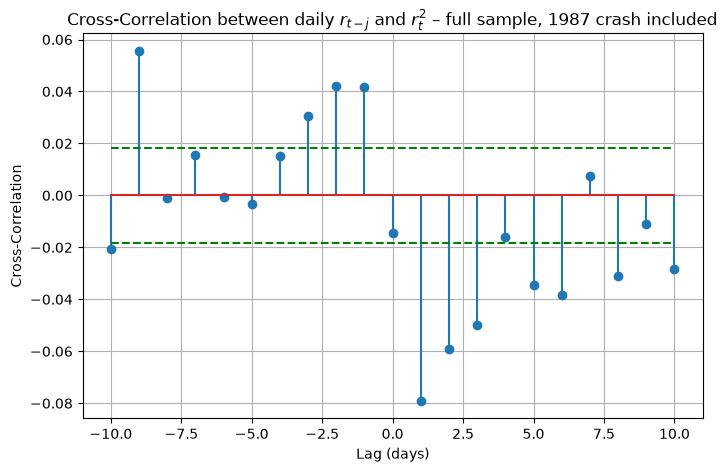

,Full sample (with 1987 crash),1988-2025 (without 1987 crash)
j,,
-10,-0.0205,-0.0363
-9,0.0556,0.0590
-8,-0.0010,0.0005
-7,0.0155,0.0134
-6,-0.0005,-0.0055
-5,-0.0032,0.0151
-4,0.0153,0.0230
-3,0.0306,0.0355
-2,0.0420,0.0259


In [133]:
cross_corr_full = cross_correlation(rt_d, rt_d**2, lag_max=lag_max)
confint_daily_full = 1.96 / np.sqrt(len(rt_d))

plt.figure(figsize=(8, 5))
plt.stem(lags, cross_corr_full)
plt.plot(lags, np.full(len(lags), confint_daily_full), color='green', linestyle='dashed')
plt.plot(lags, -np.full(len(lags), confint_daily_full), color='green', linestyle='dashed')
plt.xlabel('Lag (days)')
plt.ylabel('Cross-Correlation')
plt.title('Cross-Correlation between daily $r_{t-j}$ and $r_t^2$ – full sample, 1987 crash included')
plt.grid(True)
plt.show()

pd.DataFrame({"Full sample (with 1987 crash)": cross_correlation_table(rt_d)["Cross-correlation"],
              "1988-2025 (without 1987 crash)": cross_correlation_table(rt_d_post87)["Cross-correlation"]})

JPM vs. VIX (market implied volatility, proxy)

In [134]:
VIX = yf.download("^VIX", start="1990-01-01", end=sample_end)

VIX_d = VIX["Close"]
VIX_d = VIX_d.rename(columns={VIX_d.columns[0]: "VIX.d"})
VIX_d.index = pd.to_datetime(VIX_d.index)

merged_df = pd.merge(Pt_d, VIX_d, on='Date', how='outer')
diff_df = merged_df.diff()
merged_df = merged_df.dropna()
diff_df = diff_df.dropna()

[*********************100%***********************]  1 of 1 completed


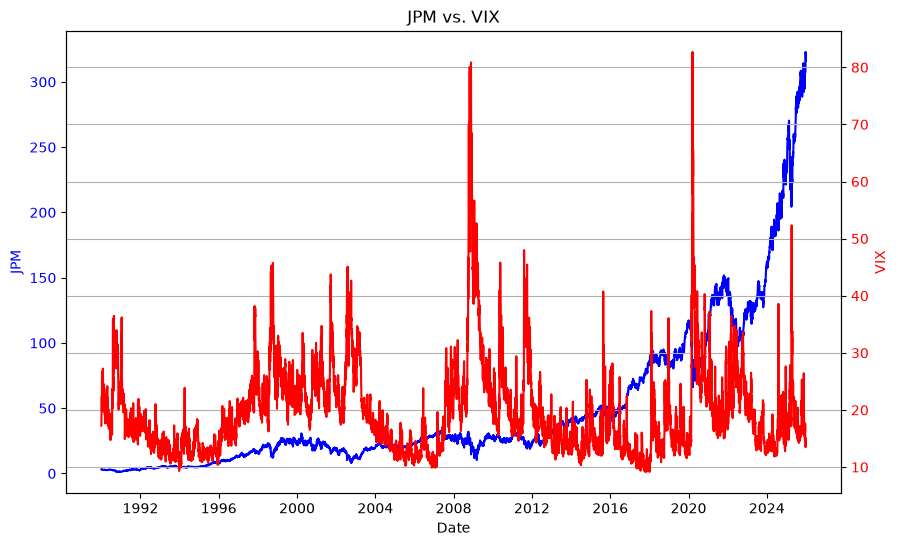

In [135]:
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(merged_df.index, merged_df['Pt.d'], label='JPM Prices', color='blue')
ax1.set_xlabel('Date')
ax1.set_ylabel('JPM', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax2 = ax1.twinx()
ax2.plot(merged_df.index, merged_df['VIX.d'], label='VIX', color='red')
ax2.set_ylabel('VIX', color='red')
ax2.tick_params(axis='y', labelcolor='red')
plt.title('JPM vs. VIX')
plt.grid(True)
plt.show()

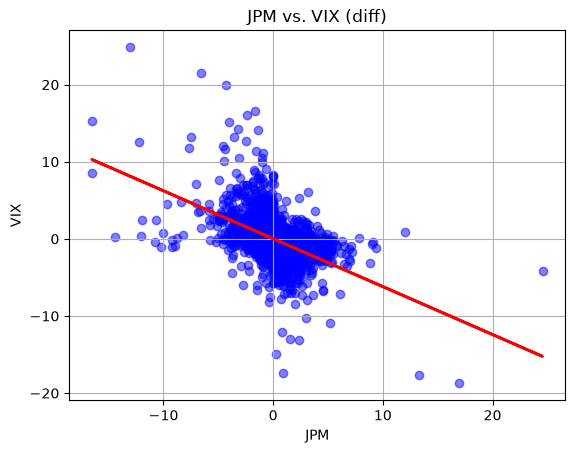

In [136]:
plt.scatter(diff_df['Pt.d'], diff_df['VIX.d'], color='blue', marker='o', alpha=0.5)
plt.xlabel('JPM')
plt.ylabel('VIX')
plt.title('JPM vs. VIX (diff)')
plt.grid(True)
coefficients = np.polyfit(diff_df['Pt.d'], diff_df['VIX.d'], 1)
regression_line = np.polyval(coefficients, diff_df['Pt.d'])
plt.plot(diff_df['Pt.d'], regression_line, color='red', linewidth=2)
plt.show()

**Regression of daily VIX changes on JPM daily log-returns (slide 143): dVIX_t = alpha + beta * r_t + e_t, one-sided test H0: beta = 0 vs H1: beta < 0**

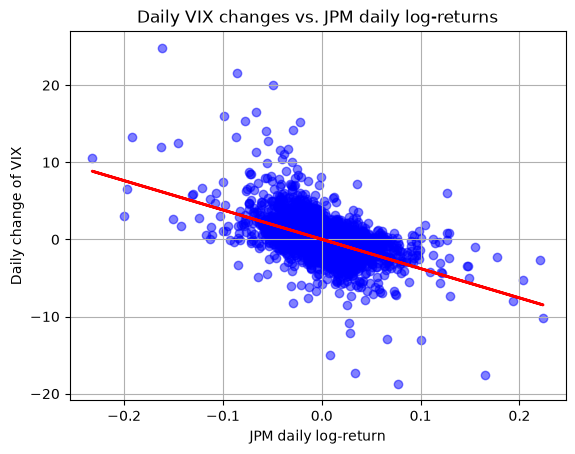

corr(r_JPM, dVIX)                     -0.5218
beta                                 -38.0199
t-stat (beta)                        -58.2324
one-sided p-value (H1: beta < 0)       0.0000
t-stat White (beta)                  -24.9131
one-sided p-value White                0.0000
R-squared                              0.2723
N                                   9066.0000
dtype: float64

In [137]:
vix_regression_data = pd.concat([rt_d.rename("r_JPM"), VIX_d["VIX.d"].diff().rename("dVIX")], axis=1).dropna()

X_vix = pd.DataFrame({"const": np.ones(len(vix_regression_data)), "r_JPM": vix_regression_data["r_JPM"]},
                     index=vix_regression_data.index)
vix_model = sm.OLS(vix_regression_data["dVIX"], X_vix).fit()
vix_model_white = vix_model.get_robustcov_results(cov_type='HC0')

plt.scatter(vix_regression_data["r_JPM"], vix_regression_data["dVIX"], color='blue', marker='o', alpha=0.5)
plt.plot(vix_regression_data["r_JPM"], vix_model.predict(X_vix), color='red', linewidth=2)
plt.xlabel('JPM daily log-return')
plt.ylabel('Daily change of VIX')
plt.title('Daily VIX changes vs. JPM daily log-returns')
plt.grid(True)
plt.show()

pd.Series({"corr(r_JPM, dVIX)": vix_regression_data.corr().iloc[0, 1],
           "beta": vix_model.params["r_JPM"],
           "t-stat (beta)": vix_model.tvalues["r_JPM"],
           "one-sided p-value (H1: beta < 0)": stats.t.cdf(vix_model.tvalues["r_JPM"], vix_model.df_resid),
           "t-stat White (beta)": vix_model_white.tvalues[1],
           "one-sided p-value White": stats.t.cdf(vix_model_white.tvalues[1], vix_model_white.df_resid),
           "R-squared": vix_model.rsquared,
           "N": int(vix_model.nobs)}).round(4)

**Asymmetric response of volatility (slide 141): dVIX_t = alpha + beta_neg * min(r_t, 0) + beta_pos * max(r_t, 0) + e_t, F-test H0: beta_neg = beta_pos**

In [138]:
X_vix_asym = pd.DataFrame({"const": np.ones(len(vix_regression_data)),
                           "r_negative": np.minimum(vix_regression_data["r_JPM"], 0),
                           "r_positive": np.maximum(vix_regression_data["r_JPM"], 0)},
                          index=vix_regression_data.index)
vix_asym_model = sm.OLS(vix_regression_data["dVIX"], X_vix_asym).fit()
vix_asym_model_white = vix_asym_model.get_robustcov_results(cov_type='HC0')
asymmetry_restriction = np.array([[0.0, 1.0, -1.0]])
asymmetry_test = vix_asym_model.f_test(asymmetry_restriction)
asymmetry_test_white = vix_asym_model_white.f_test(asymmetry_restriction)

pd.Series({"beta_neg (negative returns)": vix_asym_model.params["r_negative"],
           "t-stat beta_neg": vix_asym_model.tvalues["r_negative"],
           "beta_pos (positive returns)": vix_asym_model.params["r_positive"],
           "t-stat beta_pos": vix_asym_model.tvalues["r_positive"],
           "F-stat (H0: beta_neg = beta_pos)": float(np.squeeze(asymmetry_test.fvalue)),
           "p-value": float(np.squeeze(asymmetry_test.pvalue)),
           "t-stat White beta_neg": vix_asym_model_white.tvalues[1],
           "t-stat White beta_pos": vix_asym_model_white.tvalues[2],
           "F-stat White (H0: beta_neg = beta_pos)": float(np.squeeze(asymmetry_test_white.fvalue)),
           "p-value White": float(np.squeeze(asymmetry_test_white.pvalue)),
           "R-squared": vix_asym_model.rsquared}).round(4)

beta_neg (negative returns)               -49.0277
t-stat beta_neg                           -44.4530
beta_pos (positive returns)               -27.9297
t-stat beta_pos                           -26.7632
F-stat (H0: beta_neg = beta_pos)          152.0099
p-value                                     0.0000
t-stat White beta_neg                     -16.2687
t-stat White beta_pos                     -12.8141
F-stat White (H0: beta_neg = beta_pos)     23.9540
p-value White                               0.0000
R-squared                                   0.2843
dtype: float64

# QUESTION 2
Fama-French monthly factors: file `FF_Research_Data_Factors_monthly.csv` (monthly block only of the Kenneth French file) in the same folder as this notebook.

In [139]:
def parse_yyyymm(x):
    return pd.to_datetime(x, format="%Y%m")

FF_factors_m = pd.read_csv("FF_Research_Data_Factors_monthly.csv", sep=",", skiprows=3, header=0, parse_dates=[0], date_format=parse_yyyymm, index_col=0)

rf_m = FF_factors_m.iloc[:, 3].to_frame().rename_axis("Date")
ffm_m = FF_factors_m.iloc[:, 0:3].rename_axis("Date")

In [140]:
JPM_P_m = Pt_d.resample('ME').last()
ret_m_eq = (JPM_P_m / JPM_P_m.shift(1) - 1) * 100
ret_m_eq = ret_m_eq[1:]
ret_m_eq = ret_m_eq.rename(columns={"Pt.d": "JPM"})

ret_m_eq.index = pd.to_datetime(ret_m_eq.index, format='%Y-%m-%d').strftime('%Y-%m')
ffm_m.index = pd.to_datetime(ffm_m.index.astype(str), format='%Y%m').strftime('%Y-%m')
rf_m.index = pd.to_datetime(rf_m.index.astype(str), format='%Y%m').strftime('%Y-%m')

ret_m_all = ffm_m.join(ret_m_eq, how='inner').join(rf_m, how='inner')
ret_m_all["Mkt-RF"] = ret_m_all["Mkt-RF"] + ret_m_all["RF"]
ret_m_all = ret_m_all.rename(columns={"Mkt-RF": "CRSP_VW"})

z_m = ret_m_all.drop(["RF"], axis=1)
for col in ["CRSP_VW", "JPM"]:
    z_m[col] = ret_m_all[col] - ret_m_all["RF"]

z_m = z_m.loc[:"2025-12"]
print("Regression sample:", z_m.index[0], "to", z_m.index[-1], "- T =", len(z_m))

Regression sample: 1980-04 to 2025-12 - T = 549


**Table: OLS estimates of Model 0 (constant only), Model 1 (CAPM) and Model 2 (Fama-French 3 factors) – JPM monthly excess simple returns**

In [141]:
JPM_excess = z_m["JPM"]
MKT = z_m["CRSP_VW"]
SMB = z_m["SMB"]
HML = z_m["HML"]
T = len(z_m)

X0 = pd.DataFrame({"const": np.ones(T)}, index=z_m.index)
X1 = pd.DataFrame(np.column_stack((np.ones(T), MKT)), columns=["const", "MKT"], index=z_m.index)
X2 = pd.DataFrame(np.column_stack((np.ones(T), MKT, SMB, HML)), columns=["const", "MKT", "SMB", "HML"], index=z_m.index)

model0 = sm.OLS(JPM_excess, X0).fit()
model1 = sm.OLS(JPM_excess, X1).fit()
model2 = sm.OLS(JPM_excess, X2).fit()

summary_col([model0, model1, model2], stars=True, float_format="%.4f",
            model_names=["Model 0", "Model 1 (CAPM)", "Model 2 (FF3)"],
            info_dict={'N': lambda x: "{0:d}".format(int(x.nobs))})

,Model 0,Model 1 (CAPM),Model 2 (FF3)
const,1.1237***,0.1920,-0.0859
,(0.3813),(0.3042),(0.2839)
MKT,,1.2375***,1.3454***
,,(0.0673),(0.0651)
SMB,,,0.1581
,,,(0.0979)
HML,,,0.8714***
,,,(0.0917)
R-squared,0.0000,0.3822,0.4701
R-squared Adj.,0.0000,0.3811,0.4672


**Model 0 (constant only): full OLS output**

In [142]:
model0.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    JPM   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                       nan
Date:                Fri, 13 Nov 2026   Prob (F-statistic):                nan
Time:                        11:14:14   Log-Likelihood:                -1980.8
No. Observations:                 549   AIC:                             3964.
Df Residuals:                     548   BIC:                             3968.
Df Model:                           0                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1237      0.381      2.947      0.003       0.375       1.873
==============================================================================
Omnibus:                       27.582   Durbin-Watson:                   1.977
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               63.450
Skew:                          -0.241   Prob(JB):                     1.67e-14
Kurtosis:                       4.594   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Model 1 (CAPM): full OLS output**

In [143]:
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    JPM   R-squared:                       0.382
Model:                            OLS   Adj. R-squared:                  0.381
Method:                 Least Squares   F-statistic:                     338.4
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           3.43e-59
Time:                        11:14:14   Log-Likelihood:                -1848.6
No. Observations:                 549   AIC:                             3701.
Df Residuals:                     547   BIC:                             3710.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1920      0.304      0.631      0.528      -0.406       0.790
MKT            1.2375      0.067     18.396      0.000       1.105       1.370
==============================================================================
Omnibus:                       47.178   Durbin-Watson:                   2.106
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              184.520
Skew:                           0.263   Prob(JB):                     8.55e-41
Kurtosis:                       5.791   Cond. No.                         4.59
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Model 2 (Fama-French 3 factors): full OLS output**

In [144]:
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    JPM   R-squared:                       0.470
Model:                            OLS   Adj. R-squared:                  0.467
Method:                 Least Squares   F-statistic:                     161.2
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           8.90e-75
Time:                        11:14:14   Log-Likelihood:                -1806.4
No. Observations:                 549   AIC:                             3621.
Df Residuals:                     545   BIC:                             3638.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0859      0.284     -0.303      0.762      -0.644       0.472
MKT            1.3454      0.065     20.658      0.000       1.217       1.473
SMB            0.1581      0.098      1.615      0.107      -0.034       0.350
HML            0.8714      0.092      9.506      0.000       0.691       1.051
==============================================================================
Omnibus:                       43.005   Durbin-Watson:                   2.102
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              169.820
Skew:                           0.194   Prob(JB):                     1.33e-37
Kurtosis:                       5.697   Cond. No.                         4.80
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

White heteroskedasticity-consistent standard errors

In [145]:
def ols_vs_white_standard_errors(model):
    HC0 = model.get_robustcov_results(cov_type='HC0')
    HC3 = model.get_robustcov_results(cov_type='HC3')
    return summary_col([model, HC0, HC3], stars=True, float_format='%0.4f',
                       model_names=['OLS', "White's HC0", "White's HC3"],
                       info_dict={'N': lambda x: "{0:d}".format(int(x.nobs))})

for name, model in zip(["Model 0 (constant only)", "Model 1 (CAPM)", "Model 2 (Fama-French 3 factors)"], [model0, model1, model2]):
    print(name + ": OLS vs. White standard errors")
    display(ols_vs_white_standard_errors(model))

Model 0 (constant only): OLS vs. White standard errors


,OLS,White's HC0,White's HC3
const,1.1237***,1.1237***,1.1237***
,(0.3813),(0.3810),(0.3817)
R-squared,0.0000,0.0000,0.0000
R-squared Adj.,0.0000,0.0000,0.0000
N,549,549,549


Model 1 (CAPM): OLS vs. White standard errors


,OLS,White's HC0,White's HC3
const,0.1920,0.1920,0.1920
,(0.3042),(0.3102),(0.3118)
MKT,1.2375***,1.2375***,1.2375***
,(0.0673),(0.0779),(0.0787)
R-squared,0.3822,0.3822,0.3822
R-squared Adj.,0.3811,0.3811,0.3811
N,549,549,549


Model 2 (Fama-French 3 factors): OLS vs. White standard errors


,OLS,White's HC0,White's HC3
const,-0.0859,-0.0859,-0.0859
,(0.2839),(0.2886),(0.2919)
MKT,1.3454***,1.3454***,1.3454***
,(0.0651),(0.0751),(0.0766)
SMB,0.1581,0.1581,0.1581
,(0.0979),(0.1138),(0.1158)
HML,0.8714***,0.8714***,0.8714***
,(0.0917),(0.1043),(0.1067)
R-squared,0.4701,0.4701,0.4701
R-squared Adj.,0.4672,0.4672,0.4672


**Table: tests of restrictions on the market model and on the Fama-French model (Lecture 2 F-test), under the OLS and the White covariance matrix**

The market model is tested against beta = 1 and not against beta = 0: the question for a stock is whether it is riskier than the market, not whether it moves with the market. SMB = HML = 0 tests the Fama-French model against the CAPM. For a single restriction the F-statistic is the square of the corresponding t-statistic.

In [146]:
def restriction_test(model, restriction_matrix, restricted_value):
    model_white = model.get_robustcov_results(cov_type='HC0')
    test = model.f_test((restriction_matrix, restricted_value))
    test_white = model_white.f_test((restriction_matrix, restricted_value))
    return {"F-stat OLS": float(np.squeeze(test.fvalue)),
            "p-value OLS": float(np.squeeze(test.pvalue)),
            "F-stat White": float(np.squeeze(test_white.fvalue)),
            "p-value White": float(np.squeeze(test_white.pvalue))}


pd.DataFrame({
    "Model 1 (CAPM): alpha = 0": restriction_test(model1, np.array([[1.0, 0.0]]), 0.0),
    "Model 1 (CAPM): beta = 1": restriction_test(model1, np.array([[0.0, 1.0]]), 1.0),
    "Model 2 (FF3): alpha = 0": restriction_test(model2, np.array([[1.0, 0.0, 0.0, 0.0]]), 0.0),
    "Model 2 (FF3): beta = 1": restriction_test(model2, np.array([[0.0, 1.0, 0.0, 0.0]]), 1.0),
    "Model 2 (FF3): SMB = HML = 0": restriction_test(model2,
                                                     np.array([[0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 1.0]]),
                                                     np.array([0.0, 0.0]))
}).T.round(4)

,F-stat OLS,p-value OLS,F-stat White,p-value White
Model 1 (CAPM): alpha = 0,0.3984,0.5282,0.3831,0.5362
Model 1 (CAPM): beta = 1,12.4619,0.0005,9.2900,0.0024
Model 2 (FF3): alpha = 0,0.0916,0.7623,0.0886,0.7661
Model 2 (FF3): beta = 1,28.1270,0.0000,21.1265,0.0000
Model 2 (FF3): SMB = HML = 0,45.2022,0.0000,35.7577,0.0000


**Table: the three models estimated on simple returns and on log-returns.** The Fama-French factors are simple returns, so the regressions above use simple returns for JPM as well: $R_t - R_f$ is then the return on a self-financing position, which is the quantity the CAPM and the APT price, whereas $\ln(1+R_t) - R_f$ subtracts an arithmetic rate from a logarithmic one. The stylized facts of Question 1 use log-returns, so the models are re-estimated with $\ln(P_t/P_{t-1})$ on the left-hand side for comparison. Over a month the difference between the two is of second order, $\ln(1+R_t)\approx R_t-\tfrac{1}{2}R_t^2$, but its mean is not: it lowers the average JPM return by about $\sigma^2/2$, here $9.04^2/200\approx0.41\%$ per month, which is of the same order of magnitude as the estimated intercepts.

In [147]:
def fama_french_excess_returns(jpm_monthly_returns):
    data = ffm_m.join(jpm_monthly_returns, how='inner').join(rf_m, how='inner')
    data["CRSP_VW"] = data["Mkt-RF"] + data["RF"]
    excess = pd.DataFrame({"JPM": data["JPM"] - data["RF"],
                           "CRSP_VW": data["CRSP_VW"] - data["RF"],
                           "SMB": data["SMB"],
                           "HML": data["HML"]})
    return excess.loc[:"2025-12"]


ret_m_log = (np.log(JPM_P_m / JPM_P_m.shift(1)) * 100).iloc[1:].rename(columns={"Pt.d": "JPM"})
ret_m_log.index = pd.to_datetime(ret_m_log.index, format='%Y-%m-%d').strftime('%Y-%m')
z_m_log = fama_french_excess_returns(ret_m_log)

X1_log = pd.DataFrame(np.column_stack((np.ones(len(z_m_log)), z_m_log["CRSP_VW"])),
                      columns=["const", "MKT"], index=z_m_log.index)
X2_log = pd.DataFrame(np.column_stack((np.ones(len(z_m_log)), z_m_log["CRSP_VW"],
                                       z_m_log["SMB"], z_m_log["HML"])),
                      columns=["const", "MKT", "SMB", "HML"], index=z_m_log.index)

model0_log = sm.OLS(z_m_log["JPM"], pd.DataFrame({"const": np.ones(len(z_m_log))}, index=z_m_log.index)).fit()
model1_log = sm.OLS(z_m_log["JPM"], X1_log).fit()
model2_log = sm.OLS(z_m_log["JPM"], X2_log).fit()


def simple_versus_log_returns(models_simple, models_log):
    rows = {}
    for model_name, model_simple, model_log in zip(["Model 0", "Model 1 (CAPM)", "Model 2 (FF3)"],
                                                   models_simple, models_log):
        for parameter in model_simple.params.index:
            label = "alpha" if parameter == "const" else parameter
            rows[f"{model_name}: {label}"] = {
                "Simple returns": model_simple.params[parameter],
                "t-stat (simple)": model_simple.tvalues[parameter],
                "Log-returns": model_log.params[parameter],
                "t-stat (log)": model_log.tvalues[parameter]}
        rows[f"{model_name}: R-squared"] = {"Simple returns": model_simple.rsquared, "t-stat (simple)": "",
                                            "Log-returns": model_log.rsquared, "t-stat (log)": ""}
    return pd.DataFrame(rows).T


simple_versus_log_returns([model0, model1, model2], [model0_log, model1_log, model2_log]).round(4)

,Simple returns,t-stat (simple),Log-returns,t-stat (log)
Model 0: alpha,1.123658,2.946834,0.713429,1.847555
Model 0: R-squared,0.0,,0.0,
Model 1 (CAPM): alpha,0.192018,0.631166,-0.243988,-0.79935
Model 1 (CAPM): MKT,1.237468,18.395934,1.271708,18.842649
Model 1 (CAPM): R-squared,0.382207,,0.3936,
Model 2 (FF3): alpha,-0.085896,-0.30258,-0.521125,-1.828997
Model 2 (FF3): MKT,1.345395,20.658326,1.377686,21.076422
Model 2 (FF3): SMB,0.15813,1.615408,0.171664,1.747214
Model 2 (FF3): HML,0.871411,9.505764,0.871906,9.476213
Model 2 (FF3): R-squared,0.470106,,0.479482,


Fitted regression line of the market model (Model 1)

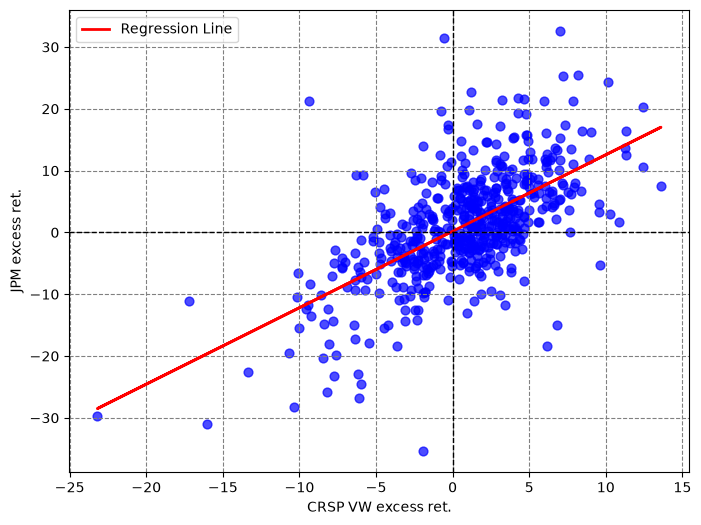

In [148]:
plt.figure(figsize=(8, 6))
plt.scatter(MKT, JPM_excess, color="blue", s=40, alpha=0.7)
plt.plot(MKT, model1.predict(X1), color="red", linewidth=2, label="Regression Line")
plt.xlabel("CRSP VW excess ret.")
plt.ylabel("JPM excess ret.")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.grid(linestyle="--", color="grey")
plt.legend()
plt.show()